# Portafolio de Acciones Colombianas (BVC)

**Juan Camilo Ospina Cardona** · Ingeniero Financiero

En este notebook usamos las acciones de la Bolsa de Valores de Colombia, se quitan las que casi no se negocian, uso todas las que quedan  comparamos diferenees portafolios
| Portafolio | Idea |
|---|---|
| **Equiponderado** | El mismo peso para todas. |
| **Mínima Varianza** | Los pesos con el menor riesgo posible. |
| **Máximo Sharpe** | Los pesos con el mejor retorno por unidad de riesgo. |
| **Sharpe Restringido** | Máximo Sharpe, pero cada acción con un peso mínimo y un peso máximo. |

Después mido el riesgo (drawdown, VaR y CVaR con 4 métodos, escenarios). Las conclusiones usan el **Monte Carlo t-Student** y pruebo los portafolios **sin mirar el futuro** (walk-forward), pagando costos de transacción.

### Contenido

0. Configuración e importaciones
1. Parámetros
2. Descarga de datos
3. Filtro de liquidez
4. Riesgo y retorno de cada acción
5. Correlaciones
6. Optimización de Markowitz
7. Frontera eficiente
8. Sharpe, Sortino, Calmar y drawdown
9. VaR y CVaR
10. Backtesting de los 4 métodos de VaR
11. Walk-forward
12. Contribución al riesgo y escenarios de estrés
13. Resumen y conclusiones


## 0. Configuración e importaciones

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import yfinance as yf
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from scipy.optimize import minimize

# Para que pandas muestre las tablas completas 
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Semilla para que las simulaciones den siempre el mismo resultado
np.random.seed(42)

# Colores (fondo negro)
negro       = '#000000'
fondo_caja  = '#0B0B0D'   # fondo de los cuadros de texto dentro de las gráficas
blanco      = '#F2F2F2'
gris        = '#8A8F98'
gris_oscuro = '#34373D'
linea       = '#1C1D20'   # líneas de la cuadrícula (muy suaves)
rojo        = '#FF4D4D'
naranja     = '#FF8A3D'
dorado      = '#FFC531'
cyan        = '#22D3EE'
verde       = '#2EE59D'
morado      = '#B388FF'
azul        = '#4D8DFF'
rosado      = '#FF6FB5'

# Un color para cada portafolio
color_equi    = cyan
color_minvar  = verde
color_sharpe  = rojo
color_restric = dorado
colores_port = [color_equi, color_minvar, color_sharpe, color_restric]

# Colores para las acciones y los sectores (si hay más elementos que colores, se repiten)
colores = [cyan, dorado, rojo, verde, morado, naranja, azul, rosado, blanco, gris]

escala_corr = 'RdYlGn'


# Estilo de todas las gráficas (plantilla de plotly)
plantilla = go.layout.Template()
plantilla.layout.paper_bgcolor = negro
plantilla.layout.plot_bgcolor = negro
plantilla.layout.font = dict(family='Inter, Segoe UI, Helvetica, Arial, sans-serif', color=blanco, size=12)
plantilla.layout.title = dict(x=0.01, xanchor='left', y=0.97, yanchor='top', font=dict(size=17))
plantilla.layout.xaxis = dict(gridcolor=linea, zerolinecolor=gris_oscuro, linecolor=gris_oscuro, showline=True,
                              ticks='outside', tickcolor=gris_oscuro, automargin=True)
plantilla.layout.yaxis = dict(gridcolor=linea, zerolinecolor=gris_oscuro, linecolor=gris_oscuro, showline=True,
                              ticks='outside', tickcolor=gris_oscuro, automargin=True)
plantilla.layout.legend = dict(bgcolor='rgba(0,0,0,0)', font=dict(size=11), orientation='h',
                               yanchor='bottom', y=1.02, xanchor='left', x=0)
plantilla.layout.hoverlabel = dict(bgcolor=fondo_caja, bordercolor=gris_oscuro, font=dict(color=blanco))
plantilla.layout.colorway = colores
plantilla.layout.height = 540
plantilla.layout.margin = dict(l=70, r=30, t=115, b=60)
plantilla.layout.bargap = 0.25

pio.templates['libro'] = plantilla
pio.templates.default = 'plotly_dark+libro'


ancho_imagen = 1100

pio.renderers.default = 'png'
pio.renderers['png'].width = ancho_imagen   
pio.renderers['png'].scale = 1.5          

## 1. Parámetros

In [2]:
# Fechas de los datos
inicio = '2021-01-15'
fin = '2026-10-15'

rf = 0.1225              # tasa libre de riesgo anual colombia
peso_min = 0.02         # peso mínimo de cada acción en el Sharpe Restringido
peso_max = 0.35        # peso máximo de cada acción en el Sharpe Restringido
capital = 100000000      # 100 millones de pesos
costo_transaccion = 0.003   # 0.3% sobre cada peso que compro o vendo (comisión + spread), en el walk-forward

# Filtro de liquidez
min_dias_con_dato = 0.90         # la acción debe tener precio al menos el 90% de los días
min_dias_con_movimiento = 0.40   # y el precio debe cambiar al menos el 40% de los días

# VaR
n_sim = 100000           # número de simulaciones de Monte Carlo
gl_candidatos = range(3, 31)   # grados de libertad de la t que pruebo (los escoge la sección 9)

# Carpeta donde guardo las imágenes para el README
carpeta = 'figuras'
os.makedirs(carpeta, exist_ok=True)

# Acciones por sector.
# Dejo por fuera las preferenciales porque se mueven casi igual que la ordinaria
# de la misma empresa y son menos líquidas:
# 'PFCIBEST', 'PFGRUPSURA', 'PFCORFICOL', 'PFAVAL', 'PFDAVVNDA', 'PFDAVIGRP', 'PFGRUPOARG', 'PFCEMARGOS'
sectores = {
    'Financiero': ['CIBEST', 'GRUPOSURA', 'CORFICOLCF', 'GRUPOAVAL', 'BOGOTA', 'OCCIDENTE',
                   'POPULAR', 'VILLAS', 'BBVACOL', 'GRUBOLIVAR', 'BVC', 'NUAMCO'],
    'Energia': ['ECOPETROL', 'TERPEL', 'CNEC'],
    'Servicios': ['ISA', 'GEB', 'PROMIGAS', 'CELSIA'],
    'Telecom': ['ETB'],
    'Industrial': ['GRUPOARGOS', 'CEMARGOS', 'CONCONCRET', 'ELCONDOR', 'ENKA', 'FABRICATO'],
    'Consumo': ['NUTRESA', 'EXITO'],
    'Mineria': ['MINEROS'],
    'Internacional': ['NUCO'],
}

sector_de = {}
for sector in sectores:
    for accion in sectores[sector]:
        sector_de[accion] = sector

# Un color para cada sector
color_sector = {}
i = 0
for sector in sectores:
    color_sector[sector] = colores[i]
    i = i + 1

print("Acciones a descargar:", len(sector_de))
print("Sectores:", len(sectores))

Acciones a descargar: 30
Sectores: 8


## 2. Descarga de datos



In [3]:

tickers = []
for accion in sector_de:
    tickers.append(accion + '.CL')

datos = yf.download(tickers, start=inicio, end=fin, auto_adjust=False, progress=False)
# Precio ajustado: incluye los dividendos
precios = datos['Adj Close']

# Le quito el ".CL" al nombre de cada columna
precios.columns = precios.columns.str.replace('.CL', '', regex=False)

# Dejo las acciones en el orden del diccionario (agrupadas por sector)
precios = precios[list(sector_de.keys())]

# Retornos simples: (precio de hoy / precio de ayer) - 1
retornos = precios / precios.shift(1) - 1
retornos = retornos.dropna(how="all")
print("Acciones descargadas:", len(precios.columns))
print("Desde:", precios.index[0].date(), "hasta:", precios.index[-1].date())
print("Días de bolsa:", len(precios))

Acciones descargadas: 30
Desde: 2021-01-15 hasta: 2026-10-14
Días de bolsa: 1496


## 3. Filtro de liquidez



In [4]:
# Porcentaje de días en que cada acción tiene precio
dias_con_dato = precios.notna().mean()

# Porcentaje de días en que el precio cambió (retorno distinto de 0)
dias_con_movimiento = (retornos.fillna(0) != 0).mean()

pasan = []
descartadas = []

for accion in precios.columns:
    tiene_datos = dias_con_dato[accion] >= min_dias_con_dato
    se_mueve = dias_con_movimiento[accion] >= min_dias_con_movimiento

    if tiene_datos and se_mueve:
        pasan.append(accion)
    else:
        descartadas.append(accion)

print("Mínimos: precio en el", f"{min_dias_con_dato:.0%}", "de los días y movimiento en el", f"{min_dias_con_movimiento:.0%}")
print("Pasan", len(pasan), "de", len(precios.columns), "acciones")
print()
print("Descartadas:")
for accion in descartadas:
    if dias_con_dato[accion] < min_dias_con_dato:
        motivo = "poca historia"
    else:
        motivo = "casi no se mueve"
    print(" ", accion, "| con dato:", round(dias_con_dato[accion] * 100), "%",
          "| con movimiento:", round(dias_con_movimiento[accion] * 100), "%", "-", motivo)

Mínimos: precio en el 90% de los días y movimiento en el 40%
Pasan 20 de 30 acciones

Descartadas:
  OCCIDENTE | con dato: 99 % | con movimiento: 11 % - casi no se mueve
  POPULAR | con dato: 99 % | con movimiento: 3 % - casi no se mueve
  VILLAS | con dato: 99 % | con movimiento: 9 % - casi no se mueve
  BBVACOL | con dato: 99 % | con movimiento: 11 % - casi no se mueve
  NUAMCO | con dato: 21 % | con movimiento: 8 % - poca historia
  ETB | con dato: 98 % | con movimiento: 34 % - casi no se mueve
  ELCONDOR | con dato: 99 % | con movimiento: 16 % - casi no se mueve
  ENKA | con dato: 98 % | con movimiento: 37 % - casi no se mueve
  FABRICATO | con dato: 99 % | con movimiento: 16 % - casi no se mueve
  NUCO | con dato: 8 % | con movimiento: 0 % - poca historia


In [5]:
retornos

Ticker,CIBEST,GRUPOSURA,CORFICOLCF,GRUPOAVAL,BOGOTA,OCCIDENTE,POPULAR,VILLAS,BBVACOL,GRUBOLIVAR,BVC,NUAMCO,ECOPETROL,TERPEL,CNEC,ISA,GEB,PROMIGAS,CELSIA,ETB,GRUPOARGOS,CEMARGOS,CONCONCRET,ELCONDOR,ENKA,FABRICATO,NUTRESA,EXITO,MINEROS,NUCO
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-18,0.010574,-0.002020,-0.005646,0.018676,-0.024940,0.00000,0.0,0.000000,0.000,0.000000,-0.003937,NaN,0.008264,0.000000,-0.001963,-0.009662,0.008059,0.000000,0.005996,0.000000,-0.007143,-0.000853,0.020707,0.042216,-0.043070,0.000000,0.000422,0.000000,-0.020979,NaN
2021-01-19,-0.017638,0.009311,0.017350,0.000000,0.018437,0.00000,0.0,0.000000,0.000,0.000000,0.000000,NaN,0.004098,0.000000,-0.000983,0.017421,0.020712,0.000000,-0.002767,-0.005600,0.004317,0.015358,0.022541,0.000000,-0.018003,0.000000,-0.000422,0.006667,0.045000,NaN
2021-01-20,-0.013695,-0.011231,-0.007752,-0.032500,0.045385,0.00000,0.0,0.000000,0.000,-0.000149,0.003952,NaN,-0.005306,0.000000,0.008858,-0.003425,0.001780,0.000000,0.014514,0.000000,-0.004298,0.003361,0.054709,0.012658,0.016667,0.000000,0.019831,0.000000,0.002506,NaN
2021-01-21,-0.008022,0.010142,0.015312,0.000000,-0.013415,0.00000,0.0,0.000000,0.011,0.000149,-0.007874,NaN,-0.011900,-0.017689,-0.006829,-0.028179,-0.001777,-0.030303,0.012834,0.004223,-0.005036,0.005025,-0.011970,0.000000,0.000000,0.000000,0.013653,0.000736,-0.010909,NaN
2021-01-22,-0.030793,-0.021687,-0.000308,-0.000861,0.007417,0.00000,0.0,0.000000,0.000,0.000000,0.007143,NaN,-0.022425,0.016206,0.006876,-0.080622,0.011036,0.012500,-0.002908,0.000467,0.005061,0.000000,-0.028846,0.000000,0.014754,0.000000,0.020000,-0.000735,0.004136,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-08,-0.015713,0.000000,-0.015094,0.000000,0.005774,0.00000,0.0,-0.020833,0.000,0.014687,-0.011976,-0.038519,0.007407,-0.005230,0.000000,0.000000,-0.003322,-0.006319,0.008475,-0.044118,0.002863,-0.001767,-0.014493,0.000000,0.005208,0.000000,-0.004497,-0.005976,0.006218,0.0
2026-10-09,0.003421,-0.000296,0.002874,0.000000,0.001566,0.02199,0.0,0.000000,0.000,-0.012608,-0.009697,0.040062,-0.007353,0.001052,0.000000,0.016028,0.003333,-0.006359,0.010504,-0.015385,-0.000951,0.017699,0.002101,0.000000,-0.005181,-0.002000,0.003074,0.014028,0.009709,0.0
2026-10-12,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


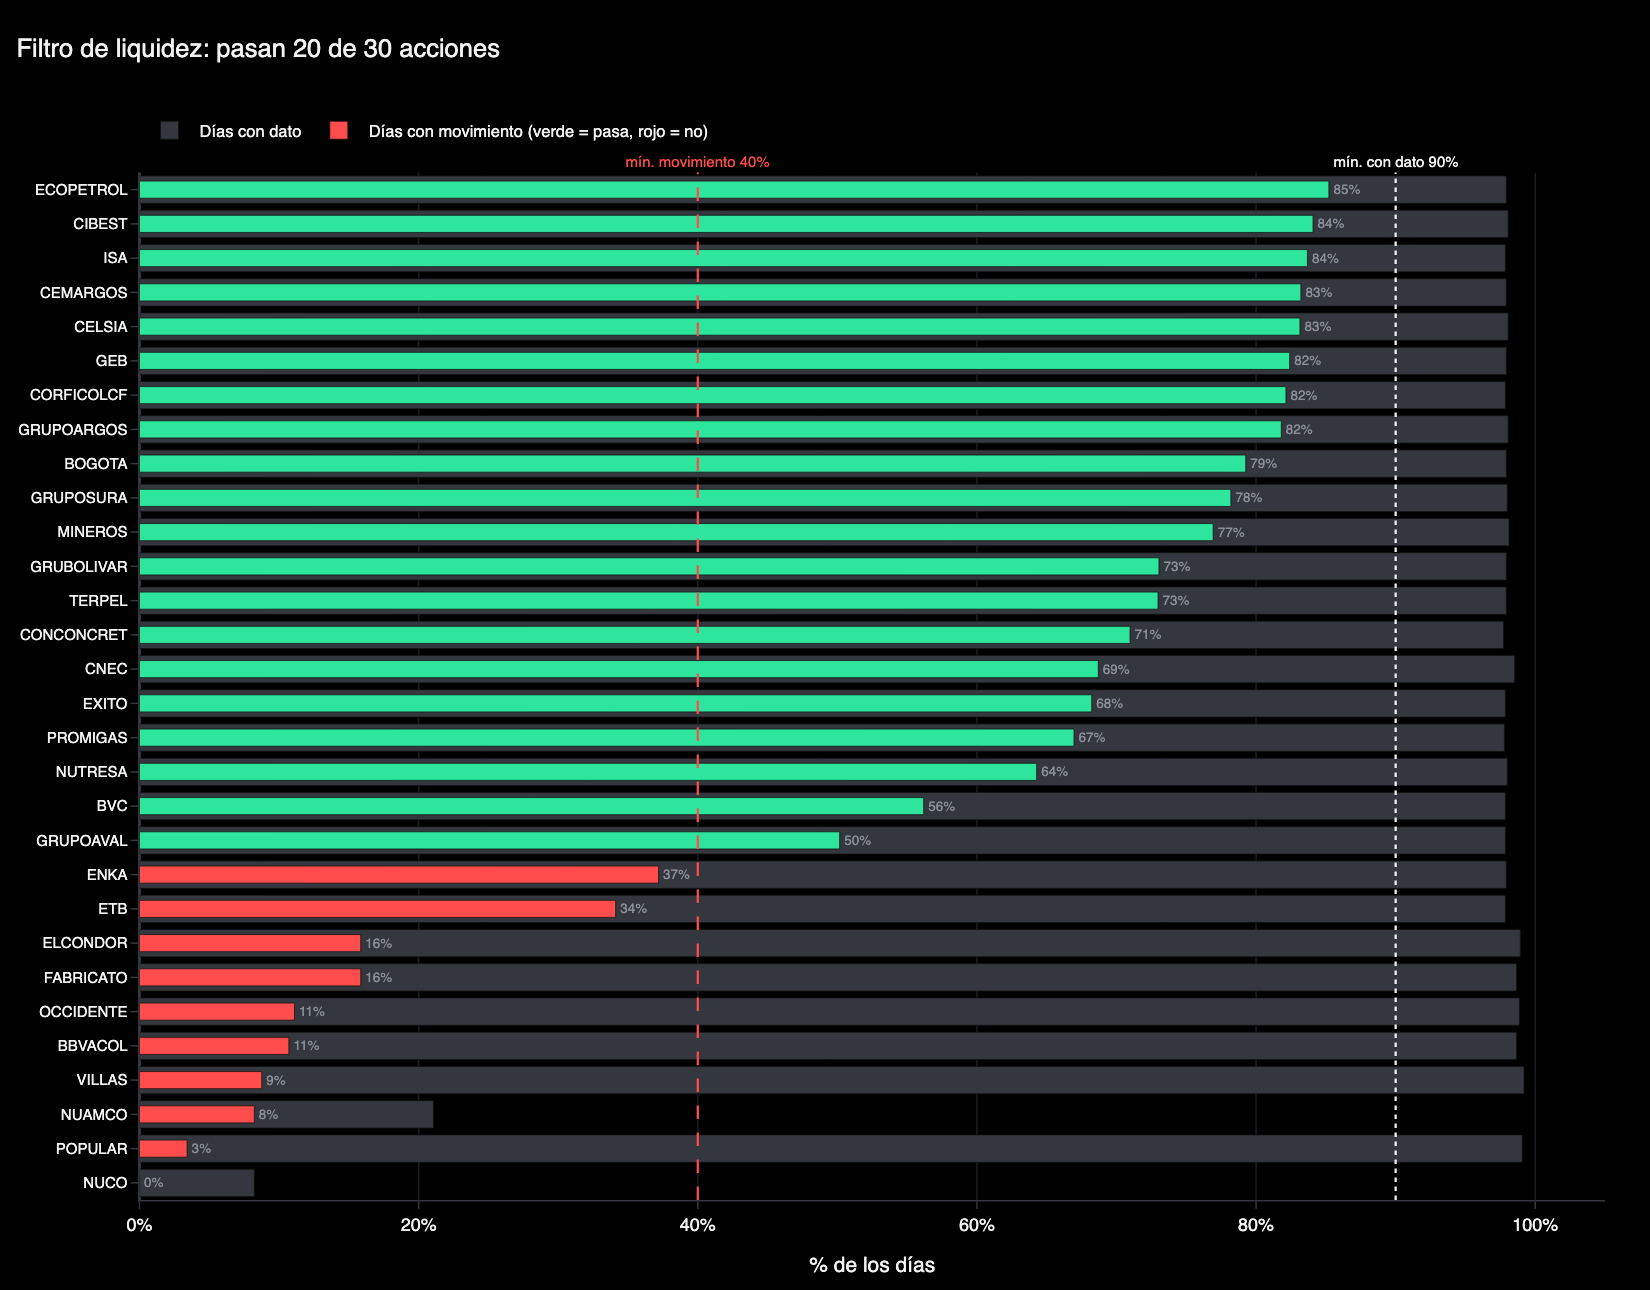

In [6]:
# Gráfica: días con dato (gris) y días con movimiento (verde = pasa, rojo = no pasa)
tabla_liquidez = pd.DataFrame({
    'Con dato': dias_con_dato,
    'Con movimiento': dias_con_movimiento,
})
tabla_liquidez = tabla_liquidez.sort_values('Con movimiento')

colores_barras = []
textos = []
for accion in tabla_liquidez.index:
    if accion in pasan:
        colores_barras.append(verde)
    else:
        colores_barras.append(rojo)
    textos.append(f"{tabla_liquidez.loc[accion, 'Con movimiento']:.0%}")

fig = go.Figure()

# Barra de fondo: días con dato
fig.add_trace(go.Bar(y=tabla_liquidez.index, x=tabla_liquidez['Con dato'] * 100, orientation='h',
                     marker=dict(color=gris_oscuro), width=0.8, name='Días con dato',
                     hovertemplate='%{y}: %{x:.0f}% de días con dato'))

# Barra de color: días con movimiento
fig.add_trace(go.Bar(y=tabla_liquidez.index, x=tabla_liquidez['Con movimiento'] * 100, orientation='h',
                     marker=dict(color=colores_barras), width=0.5, text=textos, textposition='outside',
                     textfont=dict(size=9, color=gris), cliponaxis=False,
                     name='Días con movimiento (verde = pasa, rojo = no)',
                     hovertemplate='%{y}: %{x:.0f}% de días con movimiento'))

fig.add_vline(x=min_dias_con_movimiento * 100, line_color=rojo, line_dash='dash', line_width=1.5,
              annotation=dict(text=f'mín. movimiento {min_dias_con_movimiento:.0%}',
                              font=dict(color=rojo, size=10)), annotation_position='top')
fig.add_vline(x=min_dias_con_dato * 100, line_color=blanco, line_dash='dot', line_width=1.5,
              annotation=dict(text=f'mín. con dato {min_dias_con_dato:.0%}',
                              font=dict(color=blanco, size=10)), annotation_position='top')

fig.update_xaxes(title_text='% de los días', range=[0, 105], ticksuffix='%')
fig.update_yaxes(tickfont=dict(size=10), showgrid=False)
fig.update_layout(title='Filtro de liquidez: pasan ' + str(len(pasan)) + ' de ' + str(len(precios.columns)) + ' acciones',
                  barmode='overlay', height=22 * len(tabla_liquidez) + 200)
fig.write_image(carpeta + '/filtro_liquidez.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()

## 4. Riesgo y retorno de cada acción



In [7]:
# Desde aquí trabajo solo con las acciones que pasaron el filtro
retornos_pasan = retornos[pasan]

retorno_anual = retornos_pasan.mean() * 252
volatilidad_anual = retornos_pasan.std() * np.sqrt(252)

tabla_acciones = pd.DataFrame({
    'Sector': pd.Series(sector_de)[pasan],
    'Retorno anual (%)': retorno_anual * 100,
    'Volatilidad anual (%)': volatilidad_anual * 100,
    'Retorno / Riesgo': retorno_anual / volatilidad_anual,
})
tabla_acciones = tabla_acciones.sort_values('Retorno anual (%)', ascending=False)
print(tabla_acciones.round(2))

# Acciones de cada sector que pasaron el filtro (lo uso en varias secciones)
grupos = {}
for sector in sectores:
    lista = []
    for accion in pasan:
        if sector_de[accion] == sector:
            lista.append(accion)
    if len(lista) > 0:
        grupos[sector] = lista

print()
print("Acciones que le ganaron a la tasa libre de riesgo:", (retorno_anual > rf).sum(), "de", len(pasan))
print("Acciones con retorno negativo:", (retorno_anual < 0).sum())
print("Mejor acción:", retorno_anual.idxmax(), "con", round(retorno_anual.max() * 100, 1), "% al año")
print("Acción más volátil:", volatilidad_anual.idxmax(), "con", round(volatilidad_anual.max() * 100, 1), "%")

                Sector  Retorno anual (%)  Volatilidad anual (%)  Retorno / Riesgo
NUTRESA        Consumo              61.59                  56.71              1.09
MINEROS        Mineria              33.98                  49.66              0.68
CIBEST      Financiero              31.44                  36.86              0.85
TERPEL         Energia              28.24                  28.29              1.00
GRUPOSURA   Financiero              25.24                  48.22              0.52
CEMARGOS    Industrial              19.81                  34.77              0.57
BVC         Financiero              19.77                  32.86              0.60
GRUPOARGOS  Industrial              17.62                  40.03              0.44
ECOPETROL      Energia              16.89                  36.31              0.47
GEB          Servicios              12.97                  29.33              0.44
EXITO          Consumo              12.07                  43.17              0.28
GRUB

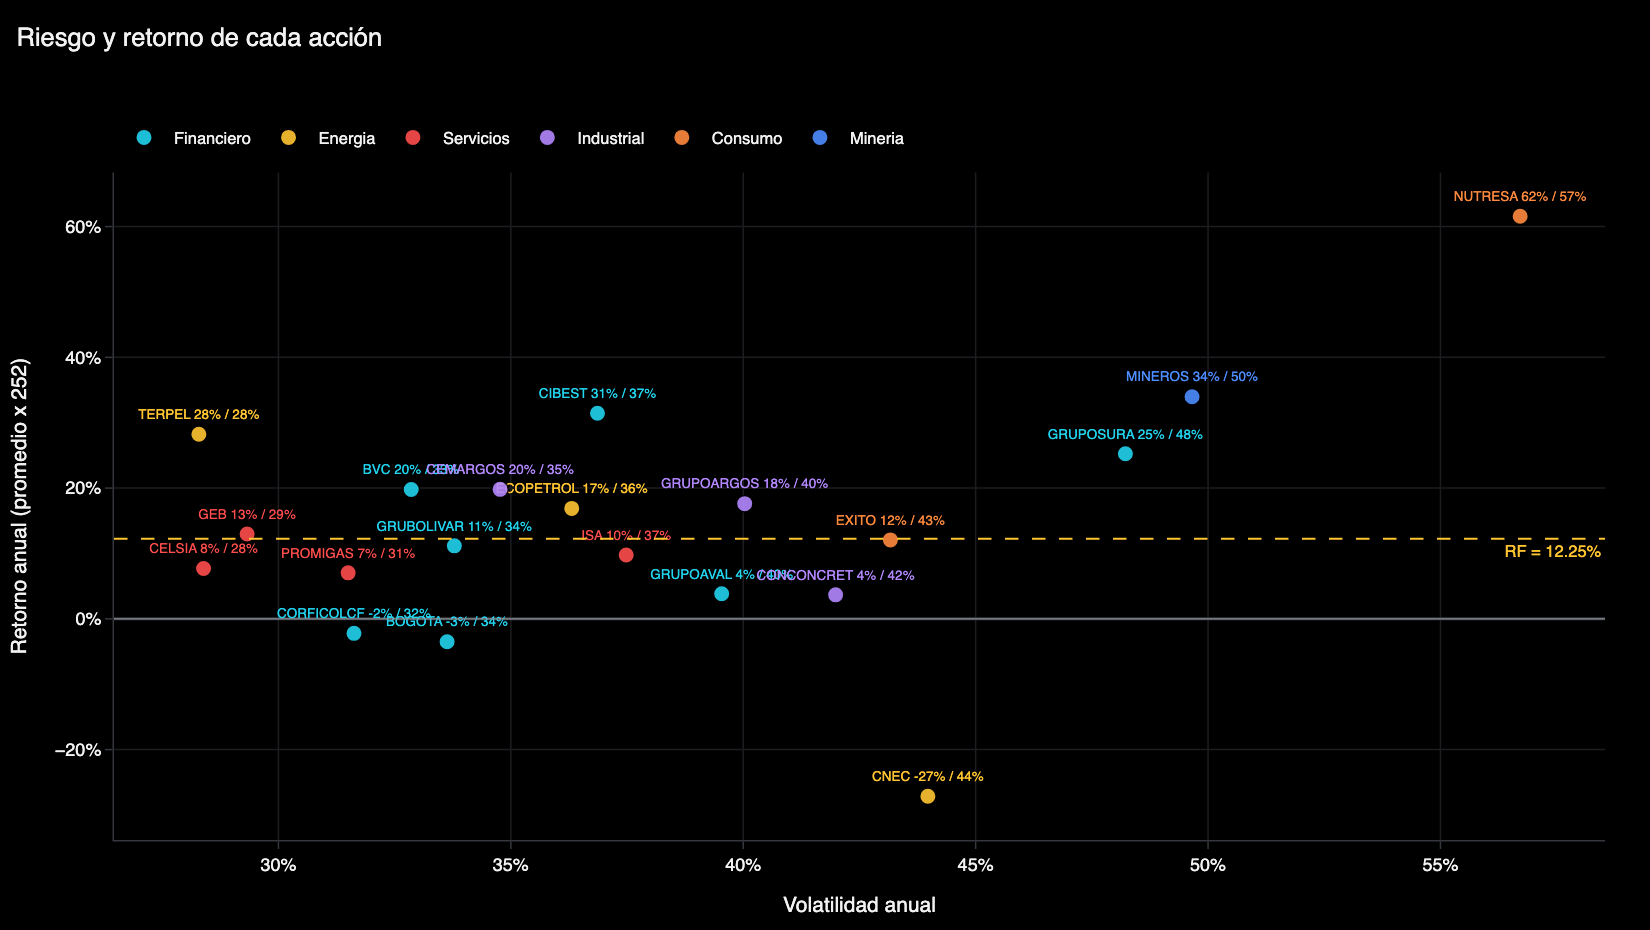

In [8]:
# Gráfica: un punto por acción, un color por sector
fig = go.Figure()

for sector in grupos:
    acciones_sector = grupos[sector]
    # Etiqueta: nombre, retorno / volatilidad
    textos = []
    for accion in acciones_sector:
        textos.append(f'{accion} {retorno_anual[accion] * 100:.0f}% / {volatilidad_anual[accion] * 100:.0f}%')

    fig.add_trace(go.Scatter(x=volatilidad_anual[acciones_sector] * 100,
                             y=retorno_anual[acciones_sector] * 100,
                             mode='markers+text', text=textos, textposition='top center',
                             textfont=dict(size=9, color=color_sector[sector]), name=sector,
                             marker=dict(size=11, color=color_sector[sector], opacity=0.9,
                                         line=dict(color=negro, width=1)),
                             hovertemplate='%{text} | Volatilidad: %{x:.1f}% | '
                                           'Retorno: %{y:.1f}%'))

fig.add_hline(y=rf * 100, line_color=dorado, line_dash='dash', line_width=1.2,
              annotation=dict(text=f'RF = {rf:.2%}', font=dict(color=dorado, size=11)),
              annotation_position='bottom right')
fig.add_hline(y=0, line_color=gris, line_width=0.8)

fig.update_xaxes(title_text='Volatilidad anual', ticksuffix='%')
fig.update_yaxes(title_text='Retorno anual (promedio x 252)', ticksuffix='%')
fig.update_layout(title='Riesgo y retorno de cada acción ', height=620)
fig.write_image(carpeta + '/riesgo_retorno.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()

## 5. Correlaciones

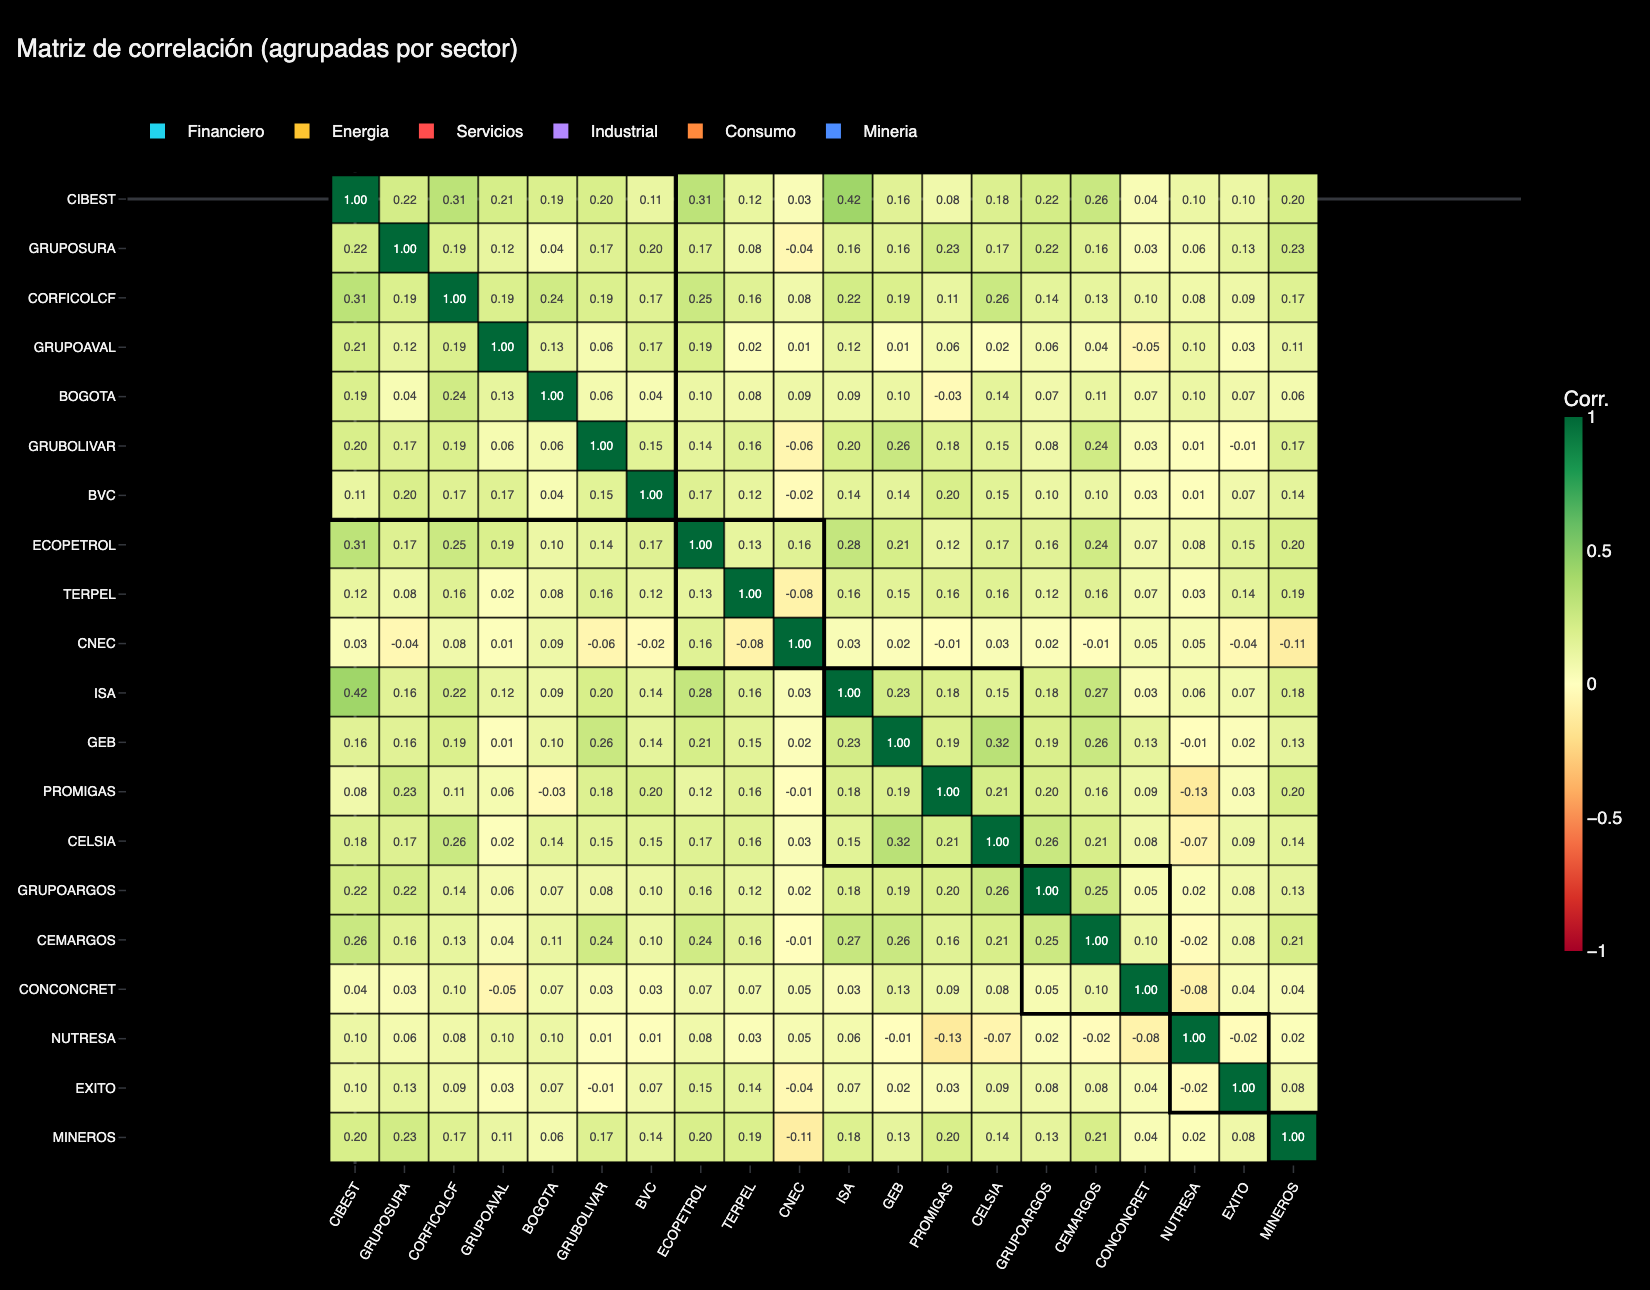

Correlación promedio entre acciones: 0.117


In [9]:
# Matriz de correlación de los retornos diarios
correlacion = retornos_pasan.corr()
total = len(correlacion)

# Texto de cada celda y nombre del par 
matriz = correlacion.values
textos_corr = []
nombres_pares = []
for fila in range(total):
    textos_fila = []
    pares_fila = []
    for col in range(total):
        pares_fila.append(pasan[fila] + ' vs ' + pasan[col])
        textos_fila.append(f'{matriz[fila, col]:.2f}')
    textos_corr.append(textos_fila)
    nombres_pares.append(pares_fila)

# Nombre de cada acción en los ejes
etiquetas = list(pasan)

posiciones = list(range(total))

fig = go.Figure(go.Heatmap(z=matriz, x=posiciones, y=posiciones, text=textos_corr, texttemplate='%{text}',
                           textfont=dict(size=8), colorscale=escala_corr, zmin=-1, zmax=1,
                           xgap=1, ygap=1, colorbar=dict(title='Corr.', len=0.6, thickness=12),
                           customdata=np.array(nombres_pares),
                           hovertemplate='%{customdata}: %{z:.2f}'))

# Un cuadro por sector
pos_inicio = 0
for sector in grupos:
    pos_fin = pos_inicio + len(grupos[sector])
    fig.add_shape(type='rect', x0=pos_inicio - 0.5, x1=pos_fin - 0.5, y0=pos_inicio - 0.5, y1=pos_fin - 0.5,
                  line=dict(color=negro, width=2.5))
    pos_inicio = pos_fin

# Leyenda de sectores: un punto de color por sector (orden de los cuadros)
for sector in grupos:
    fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers', name=sector,
                             marker=dict(size=10, color=color_sector[sector], symbol='square')))

fig.update_xaxes(tickvals=posiciones, ticktext=etiquetas, tickangle=-60, tickfont=dict(size=9),
                 showgrid=False, showline=False)
fig.update_yaxes(tickvals=posiciones, ticktext=etiquetas, tickfont=dict(size=9), autorange='reversed',
                 showgrid=False, showline=False, scaleanchor='x')
fig.update_layout(title='Matriz de correlación (agrupadas por sector)', height=860)
fig.show()

# Correlación promedio entre acciones (sin contar la diagonal, que siempre es 1)
prom_corr = (correlacion.values.sum() - total) / (total * total - total)
print("Correlación promedio entre acciones:", round(prom_corr, 3))

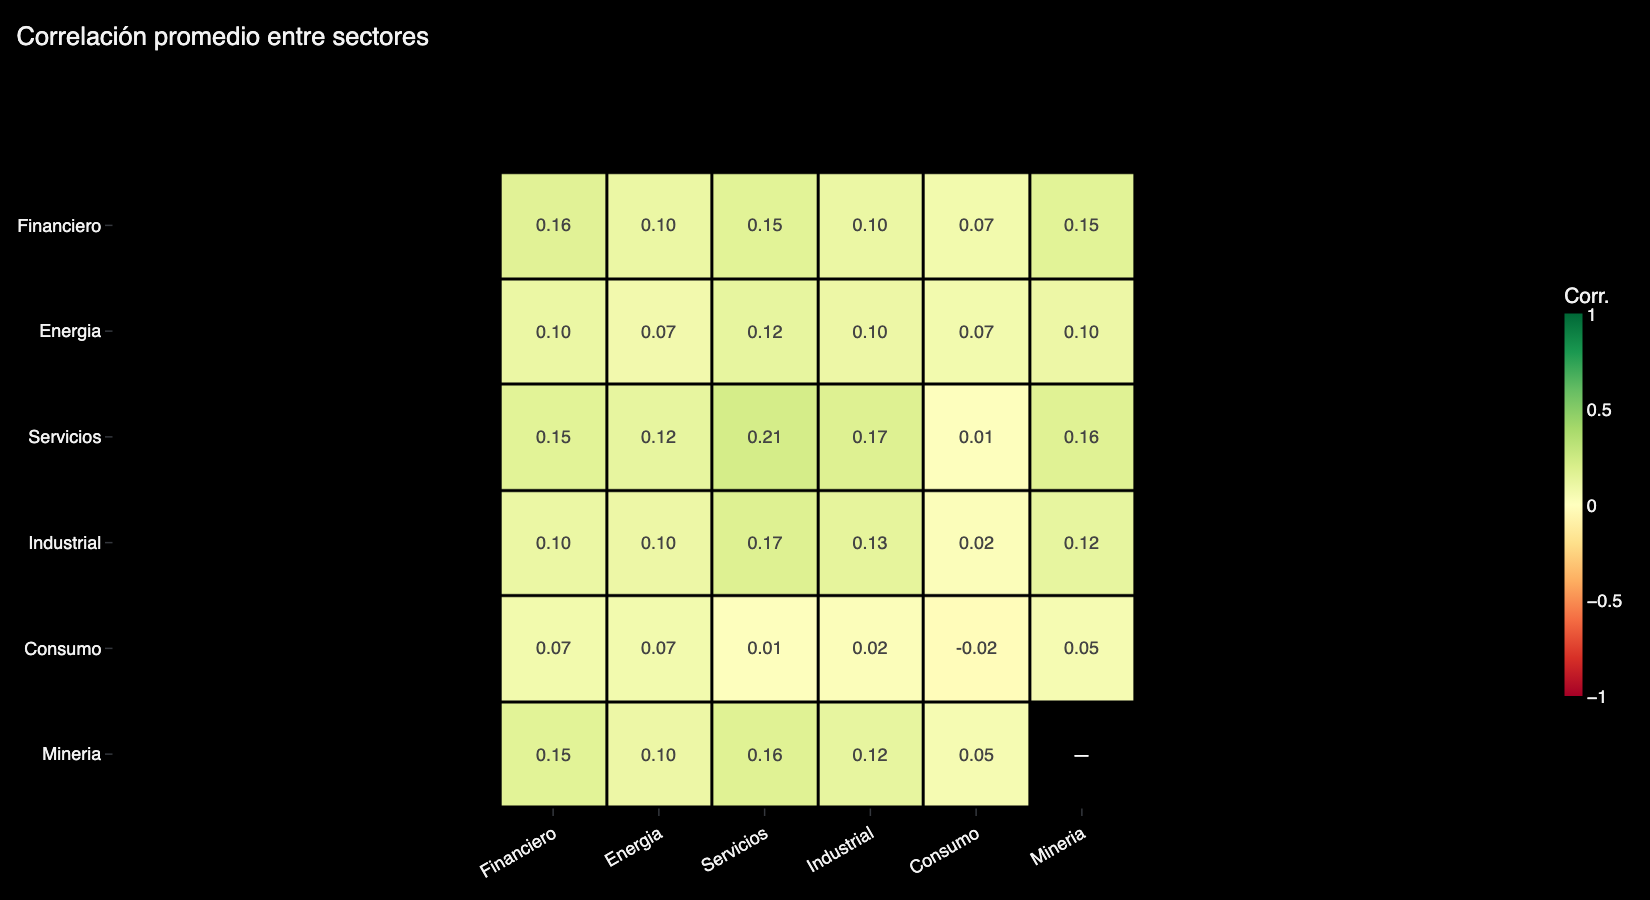

In [10]:
# Correlación promedio entre sectores
nombres_sectores = list(grupos.keys())
corr_sector = pd.DataFrame(index=nombres_sectores, columns=nombres_sectores, dtype=float)

for sector_1 in nombres_sectores:
    for sector_2 in nombres_sectores:
        # Pedazo de la matriz: filas del sector 1, columnas del sector 2
        bloque = correlacion.loc[grupos[sector_1], grupos[sector_2]].values

        if sector_1 != sector_2:
            corr_sector.loc[sector_1, sector_2] = bloque.mean()
        else:
            # Dentro del mismo sector no cuento la diagonal (cada acción consigo misma = 1)
            # Si el sector tiene una sola acción, la celda queda vacía
            k = len(grupos[sector_1])
            if k > 1:
                corr_sector.loc[sector_1, sector_2] = (bloque.sum() - k) / (k * k - k)

# Texto de cada celda (— cuando el sector tiene una sola acción)
textos_sector = []
for sector_1 in nombres_sectores:
    textos_fila = []
    for sector_2 in nombres_sectores:
        valor = corr_sector.loc[sector_1, sector_2]
        if np.isnan(valor):
            textos_fila.append('—')
        else:
            textos_fila.append(f'{valor:.2f}')
    textos_sector.append(textos_fila)

fig = go.Figure(go.Heatmap(z=corr_sector.values, x=nombres_sectores, y=nombres_sectores,
                           text=textos_sector, texttemplate='%{text}', textfont=dict(size=12),
                           colorscale=escala_corr, zmin=-1, zmax=1, xgap=2, ygap=2,
                           colorbar=dict(title='Corr.', len=0.7, thickness=12),
                           hovertemplate='%{y} vs %{x}: %{z:.2f}'))
fig.update_xaxes(showgrid=False, showline=False, tickangle=-30)
fig.update_yaxes(showgrid=False, showline=False, autorange='reversed', scaleanchor='x')
fig.update_layout(title='Correlación promedio entre sectores',
                  height=600)
fig.write_image(carpeta + '/correlacion_sectores.png', scale=2, width=850)   # imagen para el README
fig.show()

## 6. Optimización de Markowitz



In [11]:
# Uso todas las acciones que pasaron el filtro y dejo que el optimizador escoja la mejor combinación
portafolio_final = list(pasan)

# Solo los días en que todas las acciones tienen dato
retornos_portafolio = retornos[portafolio_final].dropna()
activos = list(retornos_portafolio.columns)
n = len(activos)

# Retorno esperado y matriz de covarianza, anuales
mu = retornos_portafolio.mean().values * 252
cov = retornos_portafolio.cov().values * 252

# Volatilidad de cada acción sola
vol_acciones = np.sqrt(np.diag(cov))

# Retornos diarios como matriz de numpy (filas = días, columnas = acciones)
# Con esto armo el retorno del portafolio: matriz x pesos
matriz_retornos = retornos_portafolio.values

print("Acciones del portafolio:", activos)
print("Días con dato para todas:", len(retornos_portafolio), "de", len(retornos))

Acciones del portafolio: ['CIBEST', 'GRUPOSURA', 'CORFICOLCF', 'GRUPOAVAL', 'BOGOTA', 'GRUBOLIVAR', 'BVC', 'ECOPETROL', 'TERPEL', 'CNEC', 'ISA', 'GEB', 'PROMIGAS', 'CELSIA', 'GRUPOARGOS', 'CEMARGOS', 'CONCONCRET', 'NUTRESA', 'EXITO', 'MINEROS']
Días con dato para todas: 1425 de 1495


In [12]:
# minimize necesita recibir funciones, por eso aquí defino las pocas que uso en el notebook.
# Todas parten de la serie diaria de retornos simples del portafolio.

def serie_portafolio(w, matriz_retornos):
    # Retorno simple de cada día: suma de w_i * r_i
    return np.dot(matriz_retornos, w)


def retorno_portafolio(w, matriz_retornos):
    # Retorno anual = promedio diario x 252
    r_p = serie_portafolio(w, matriz_retornos)
    return np.mean(r_p) * 252


def volatilidad(w, matriz_retornos):
    # Volatilidad anual = desviación diaria x raíz de 252 (ddof=1, igual que pandas)
    r_p = serie_portafolio(w, matriz_retornos)
    return np.std(r_p, ddof=1) * np.sqrt(252)


def sharpe_negativo(w, matriz_retornos):
    # Signo menos porque minimize solo sabe minimizar
    sharpe = (retorno_portafolio(w, matriz_retornos) - rf) / volatilidad(w, matriz_retornos)
    return -sharpe


def suma_uno(w):
    # Condición: los pesos deben sumar 1 (minimize pide que esto dé 0)
    return np.sum(w) - 1


def llega_al_objetivo(w, objetivo):
    # Condición de la frontera: el retorno debe ser igual al objetivo (esto debe dar 0)
    return retorno_portafolio(w, matriz_retornos) - objetivo

In [13]:
pesos_iniciales = np.ones(n) / n                   # arranco con pesos iguales
restricciones = [{'type': 'eq', 'fun': suma_uno}]  # los pesos suman 1
limites = [(0, 1)] * n                             # cada peso entre 0% y 100%
limites_restringido = [(peso_min, peso_max)] * n   # cada peso entre el mínimo y el máximo

# 1. Equiponderado
w_equi = np.ones(n) / n

# 2. Mínima varianza
resultado = minimize(volatilidad, pesos_iniciales, args=(matriz_retornos,), method='SLSQP',
                     bounds=limites, constraints=restricciones)
w_minvar = resultado.x

# 3. Máximo Sharpe
resultado = minimize(sharpe_negativo, pesos_iniciales, args=(matriz_retornos,), method='SLSQP',
                     bounds=limites, constraints=restricciones)
w_sharpe = resultado.x

# 4. Sharpe Restringido (mismo problema, pero con límites por acción)
resultado = minimize(sharpe_negativo, pesos_iniciales, args=(matriz_retornos,), method='SLSQP',
                     bounds=limites_restringido, constraints=restricciones)
w_restric = resultado.x

# Guardo los cuatro juntos para usarlos en el resto del notebook
nombres = ['Equiponderado', 'Mínima Varianza', 'Máximo Sharpe', 'Sharpe Restringido']
lista_pesos = [w_equi, w_minvar, w_sharpe, w_restric]


In [14]:
# Tabla de pesos (%)
tabla_pesos = pd.DataFrame(index=activos)
for i in range(4):
    tabla_pesos[nombres[i]] = lista_pesos[i] * 100

print("PESOS (%):")
print(tabla_pesos.round(1))

# Tabla de métricas (con los mismos datos que usé para optimizar)
tabla_comparacion = pd.DataFrame(index=nombres, columns=['Retorno', 'Volatilidad', 'Sharpe'], dtype=float)
for i in range(4):
    w = lista_pesos[i]
    ret = retorno_portafolio(w, matriz_retornos)
    vol = volatilidad(w, matriz_retornos)
    tabla_comparacion.loc[nombres[i]] = [ret, vol, (ret - rf) / vol]

print()
print("MÉTRICAS:")
print(tabla_comparacion.round(3))

print()
print("Volatilidad promedio de las acciones solas:", round(vol_acciones.mean() * 100, 1), "%")
print("Volatilidad con pesos iguales:", round(tabla_comparacion.loc['Equiponderado', 'Volatilidad'] * 100, 1), "%")
print("-> Solo con repartir la plata el riesgo baja bastante.")

# Comprobación: con retornos simples la fórmula clásica da exactamente la misma volatilidad
cov_diaria = retornos_portafolio.cov().values
vol_clasica = np.sqrt(np.dot(w_sharpe, np.dot(cov_diaria, w_sharpe))) * np.sqrt(252)
print("Volatilidad Máximo Sharpe con la serie diaria:", round(volatilidad(w_sharpe, matriz_retornos) * 100, 4), "%")
print("Volatilidad Máximo Sharpe con raíz(w' Σ w):   ", round(vol_clasica * 100, 4), "%")

PESOS (%):
            Equiponderado  Mínima Varianza  Máximo Sharpe  Sharpe Restringido
CIBEST                5.0              0.2           17.9                 9.8
GRUPOSURA             5.0              0.0            1.7                 2.0
CORFICOLCF            5.0              1.1            0.0                 2.0
GRUPOAVAL             5.0              7.2            0.0                 2.0
BOGOTA                5.0              7.9            0.0                 2.0
GRUBOLIVAR            5.0              6.8            0.0                 2.0
BVC                   5.0              7.0            7.3                 2.0
ECOPETROL             5.0              0.0            0.0                 2.0
TERPEL                5.0             12.5           28.9                17.4
CNEC                  5.0              8.7            0.0                 2.0
ISA                   5.0              0.8            0.0                 2.0
GEB                   5.0              6.6           

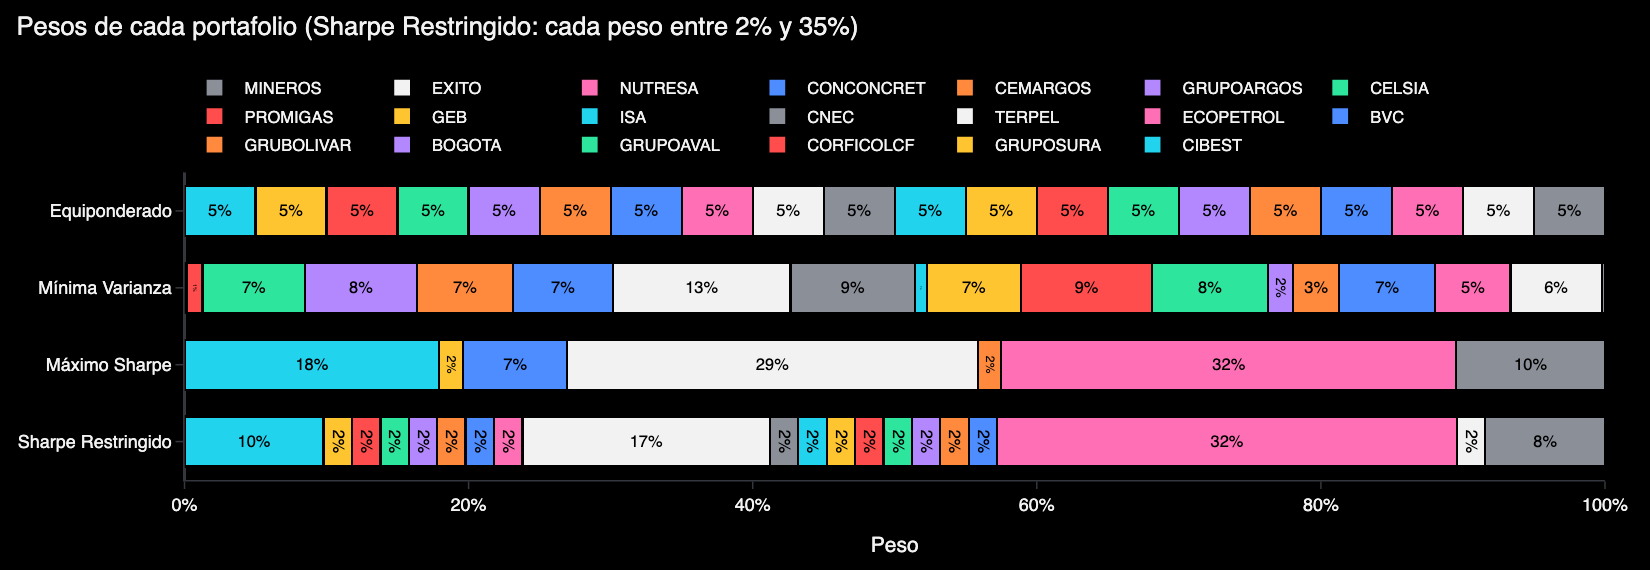

In [15]:
# Gráfica: pesos de cada portafolio
fig = go.Figure()

for j in range(n):
    valores = tabla_pesos.loc[activos[j]].values

    # Escribo el porcentaje de todas las acciones que tienen peso (plotly achica la letra si no cabe)
    textos = []
    for v in valores:
        if v >= 0.5:
            textos.append(f'{v:.0f}%')
        else:
            textos.append('')

    fig.add_trace(go.Bar(y=nombres, x=valores, orientation='h', name=activos[j],
                         marker=dict(color=colores[j % len(colores)], line=dict(color=negro, width=1.5)),
                         text=textos, textposition='inside', insidetextanchor='middle',
                         textfont=dict(color=negro, size=11), constraintext='inside',
                         hovertemplate=activos[j] + ': %{x:.1f}%'))

fig.update_xaxes(title_text='Peso', range=[0, 100], ticksuffix='%', showgrid=False)
fig.update_yaxes(autorange='reversed', showgrid=False)
fig.update_layout(title=f'Pesos de cada portafolio (Sharpe Restringido: cada peso entre {peso_min:.0%} y {peso_max:.0%})',
                  barmode='stack', height=380, bargap=0.35)
fig.write_image(carpeta + '/pesos.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()

## 7. Frontera eficiente


In [16]:
# Paso 1: portafolios al azar
# np.random.dirichlet da pesos al azar que suman 1.
# Con 1 salen repartidos; con 0.2 salen concentrados en pocas acciones.
pesos_repartidos = np.random.dirichlet(np.ones(n), 10000)
pesos_concentrados = np.random.dirichlet(np.ones(n) * 0.2, 10000)
pesos_azar = np.vstack([pesos_repartidos, pesos_concentrados])

ret_azar = []
vol_azar = []
for w in pesos_azar:
    r_p = serie_portafolio(w, matriz_retornos)         # retorno simple diario de este portafolio
    ret_azar.append(np.mean(r_p) * 252)
    vol_azar.append(np.std(r_p, ddof=1) * np.sqrt(252))

ret_azar = np.array(ret_azar)
vol_azar = np.array(vol_azar)
sharpe_azar = (ret_azar - rf) / vol_azar

# Paso 2: la frontera
# Con retornos simples el retorno del portafolio es un promedio ponderado,
# así que el retorno máximo es el de la mejor acción sola (100% en ella)
ret_maximo = mu.max()

retornos_objetivo = np.linspace(mu.min(), ret_maximo, 60)

vol_frontera = []
ret_frontera = []
pesos_frontera = []

for objetivo in retornos_objetivo:
    condiciones = [{'type': 'eq', 'fun': suma_uno},
                   {'type': 'eq', 'fun': llega_al_objetivo, 'args': (objetivo,)}]

    resultado = minimize(volatilidad, pesos_iniciales, args=(matriz_retornos,), method='SLSQP',
                         bounds=limites, constraints=condiciones)

    vol_frontera.append(resultado.fun)
    ret_frontera.append(objetivo)
    pesos_frontera.append(resultado.x)

vol_frontera = np.array(vol_frontera)
ret_frontera = np.array(ret_frontera)
pesos_frontera = np.array(pesos_frontera)

# La parte eficiente es de la mínima varianza hacia arriba
ret_minvar = tabla_comparacion.loc['Mínima Varianza', 'Retorno']
eficiente = ret_frontera >= ret_minvar - 0.000001

# Paso 3: CML (sale de la rf con pendiente = Sharpe máximo)
sharpe_max = tabla_comparacion.loc['Máximo Sharpe', 'Sharpe']
vol_sharpe = tabla_comparacion.loc['Máximo Sharpe', 'Volatilidad']
x_cml = np.linspace(0, vol_sharpe * 1.5, 50)
y_cml = rf + sharpe_max * x_cml

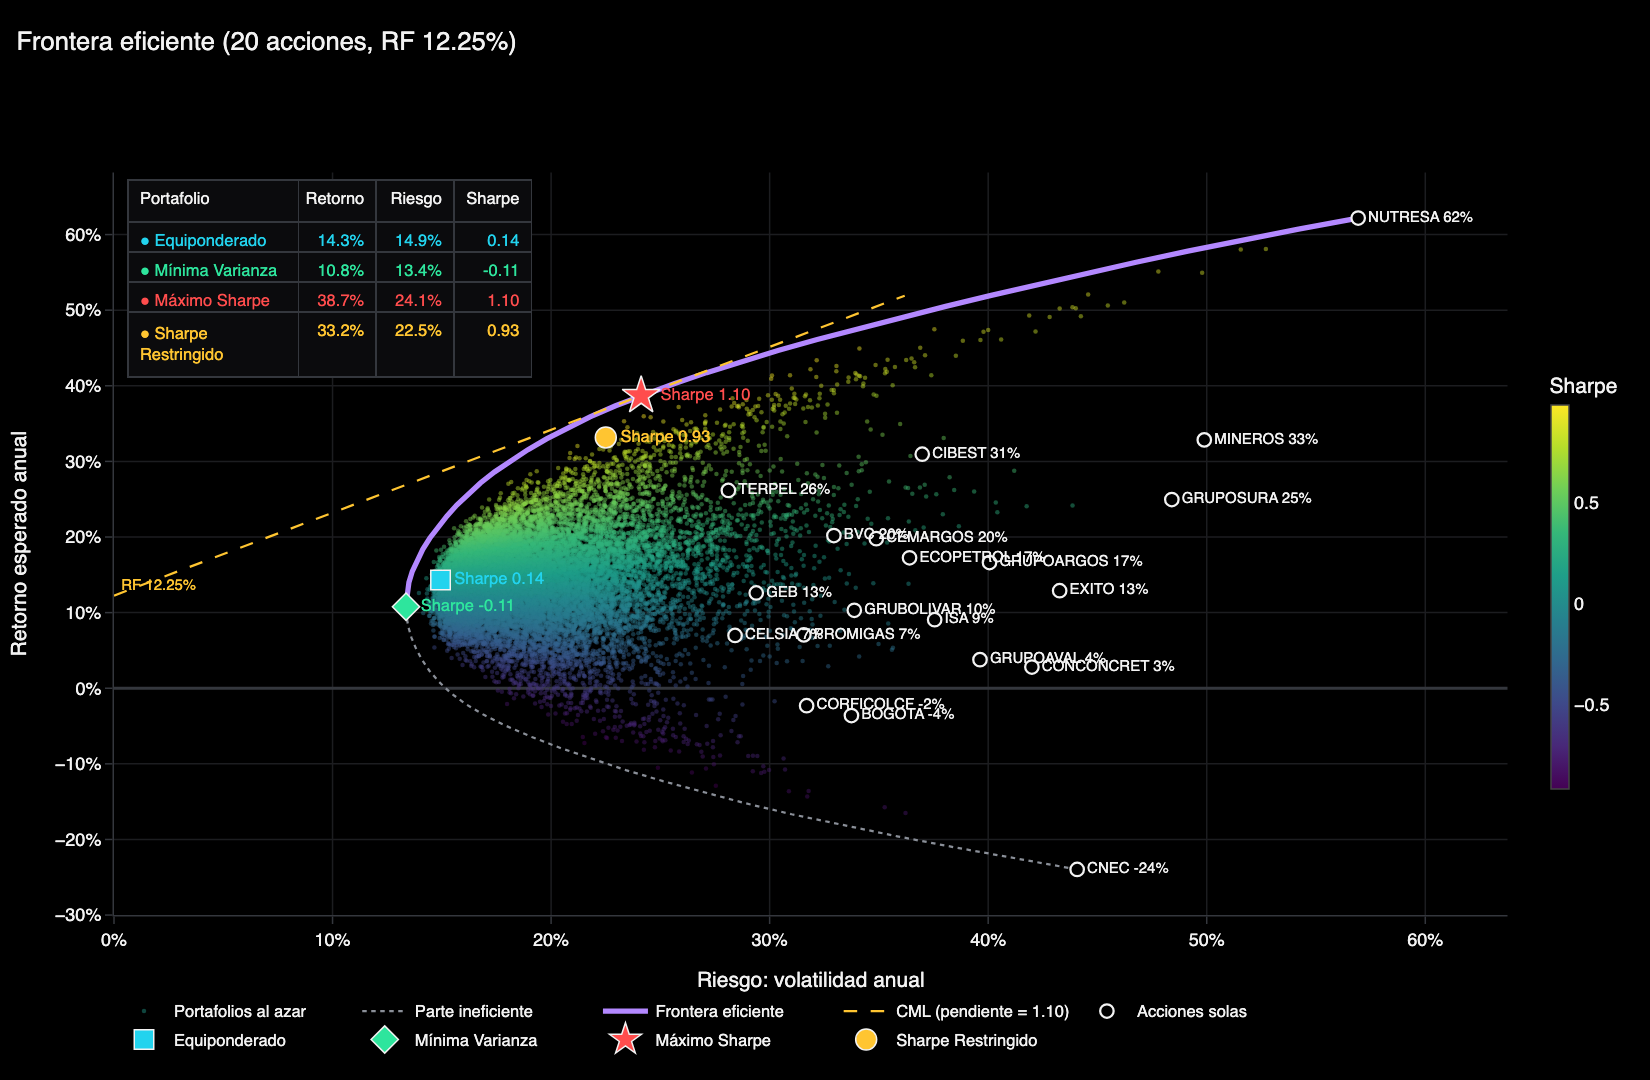

In [17]:
# Valores de los cuatro portafolios para la gráfica
ret_equi = tabla_comparacion.loc['Equiponderado', 'Retorno']
vol_equi = tabla_comparacion.loc['Equiponderado', 'Volatilidad']
vol_minvar = tabla_comparacion.loc['Mínima Varianza', 'Volatilidad']
ret_sharpe = tabla_comparacion.loc['Máximo Sharpe', 'Retorno']
ret_restric = tabla_comparacion.loc['Sharpe Restringido', 'Retorno']
vol_restric = tabla_comparacion.loc['Sharpe Restringido', 'Volatilidad']

fig = go.Figure()

# Nube de portafolios al azar, coloreados por Sharpe
fig.add_trace(go.Scatter(x=vol_azar * 100, y=ret_azar * 100, mode='markers', name='Portafolios al azar',
                         marker=dict(size=3, color=sharpe_azar, colorscale='Viridis', opacity=0.45,
                                     colorbar=dict(title='Sharpe', len=0.6, thickness=12, y=0.45)),
                         hovertemplate='Riesgo: %{x:.1f}% | Retorno: %{y:.1f}%'))

# Frontera (ineficiente punteada, eficiente gruesa)
fig.add_trace(go.Scatter(x=vol_frontera[~eficiente] * 100, y=ret_frontera[~eficiente] * 100, mode='lines',
                         name='Parte ineficiente', line=dict(color=gris, width=1.5, dash='dot')))
# Sharpe de cada punto de la frontera (para verlo al pasar el mouse)
sharpe_frontera = (ret_frontera[eficiente] - rf) / vol_frontera[eficiente]
fig.add_trace(go.Scatter(x=vol_frontera[eficiente] * 100, y=ret_frontera[eficiente] * 100, mode='lines',
                         name='Frontera eficiente', line=dict(color=morado, width=3.5), text=sharpe_frontera,
                         hovertemplate='Riesgo: %{x:.1f}% | Retorno: %{y:.1f}% | Sharpe: %{text:.2f}'))

# CML
fig.add_trace(go.Scatter(x=x_cml * 100, y=y_cml * 100, mode='lines',
                         name=f'CML (pendiente = {sharpe_max:.2f})',
                         line=dict(color=dorado, width=1.5, dash='dash')))
# Dónde arranca la CML: la tasa libre de riesgo
fig.add_annotation(x=0, y=rf * 100, text=f' RF {rf:.2%}', showarrow=False, xanchor='left',
                   yanchor='bottom', font=dict(size=10, color=dorado))

# Cada acción sola (nombre y retorno)
textos_acciones = []
for j in range(n):
    textos_acciones.append(f'{activos[j]} {mu[j] * 100:.0f}%')

fig.add_trace(go.Scatter(x=vol_acciones * 100, y=mu * 100, mode='markers+text', text=textos_acciones,
                         textposition='middle right', textfont=dict(size=10, color=blanco), name='Acciones solas',
                         marker=dict(size=9, color=negro, line=dict(color=blanco, width=1.5)),
                         hovertemplate='%{text} | Riesgo: %{x:.1f}% | Retorno: %{y:.1f}%'))

# Los cuatro portafolios: [riesgo, retorno, nombre, color, símbolo, tamaño]
puntos = [[vol_equi, ret_equi, 'Equiponderado', color_equi, 'square', 13],
          [vol_minvar, ret_minvar, 'Mínima Varianza', color_minvar, 'diamond', 14],
          [vol_sharpe, ret_sharpe, 'Máximo Sharpe', color_sharpe, 'star', 19],
          [vol_restric, ret_restric, 'Sharpe Restringido', color_restric, 'circle', 14]]

# Cada portafolio con su Sharpe escrito al lado
for punto in puntos:
    riesgo = punto[0]
    retorno = punto[1]
    nombre = punto[2]
    color = punto[3]
    sharpe_punto = (retorno - rf) / riesgo

    fig.add_trace(go.Scatter(x=[riesgo * 100], y=[retorno * 100], mode='markers+text', name=nombre,
                             text=[f'Sharpe {sharpe_punto:.2f}'], textposition='middle right',
                             textfont=dict(size=11, color=color),
                             marker=dict(size=punto[5], color=color, symbol=punto[4],
                                         line=dict(color=blanco, width=1)),
                             hovertemplate=f'{nombre} | Riesgo: %{{x:.1f}}% | Retorno: %{{y:.1f}}%'))

# Cuadro con los valores de los cuatro portafolios (arriba a la izquierda)
nombres_cuadro = []
retornos_cuadro = []
riesgos_cuadro = []
sharpes_cuadro = []
colores_cuadro = []
for punto in puntos:
    nombres_cuadro.append('● ' + punto[2])
    retornos_cuadro.append(f'{punto[1]:.1%}')
    riesgos_cuadro.append(f'{punto[0]:.1%}')
    sharpes_cuadro.append(f'{(punto[1] - rf) / punto[0]:.2f}')
    colores_cuadro.append(punto[3])

fig.add_trace(go.Table(domain=dict(x=[0.01, 0.3], y=[0.72, 0.99]),    # posición dentro de la gráfica
                       columnwidth=[2.2, 1, 1, 1],
                       header=dict(values=['Portafolio', 'Retorno', 'Riesgo', 'Sharpe'],
                                   fill_color=fondo_caja, line_color=gris_oscuro,
                                   font=dict(color=blanco, size=11), align=['left', 'right']),
                       cells=dict(values=[nombres_cuadro, retornos_cuadro, riesgos_cuadro, sharpes_cuadro],
                                  fill_color=fondo_caja, line_color=gris_oscuro,
                                  font=dict(color=[colores_cuadro] * 4, size=11),   # cada fila con el color de su portafolio
                                  align=['left', 'right'])))

maximo_x = max(vol_acciones.max(), vol_azar.max()) * 100 * 1.12
fig.update_xaxes(title_text='Riesgo: volatilidad anual', range=[0, maximo_x], ticksuffix='%')
fig.update_yaxes(title_text='Retorno esperado anual', ticksuffix='%')
fig.update_layout(title=f'Frontera eficiente ({n} acciones, RF {rf:.2%})', height=720,
                  legend=dict(orientation='h', yanchor='top', y=-0.1, x=0), margin=dict(b=110))
fig.write_image(carpeta + '/frontera_eficiente.png', scale=2, width=ancho_imagen, height=720)   # imagen para el README
fig.show()

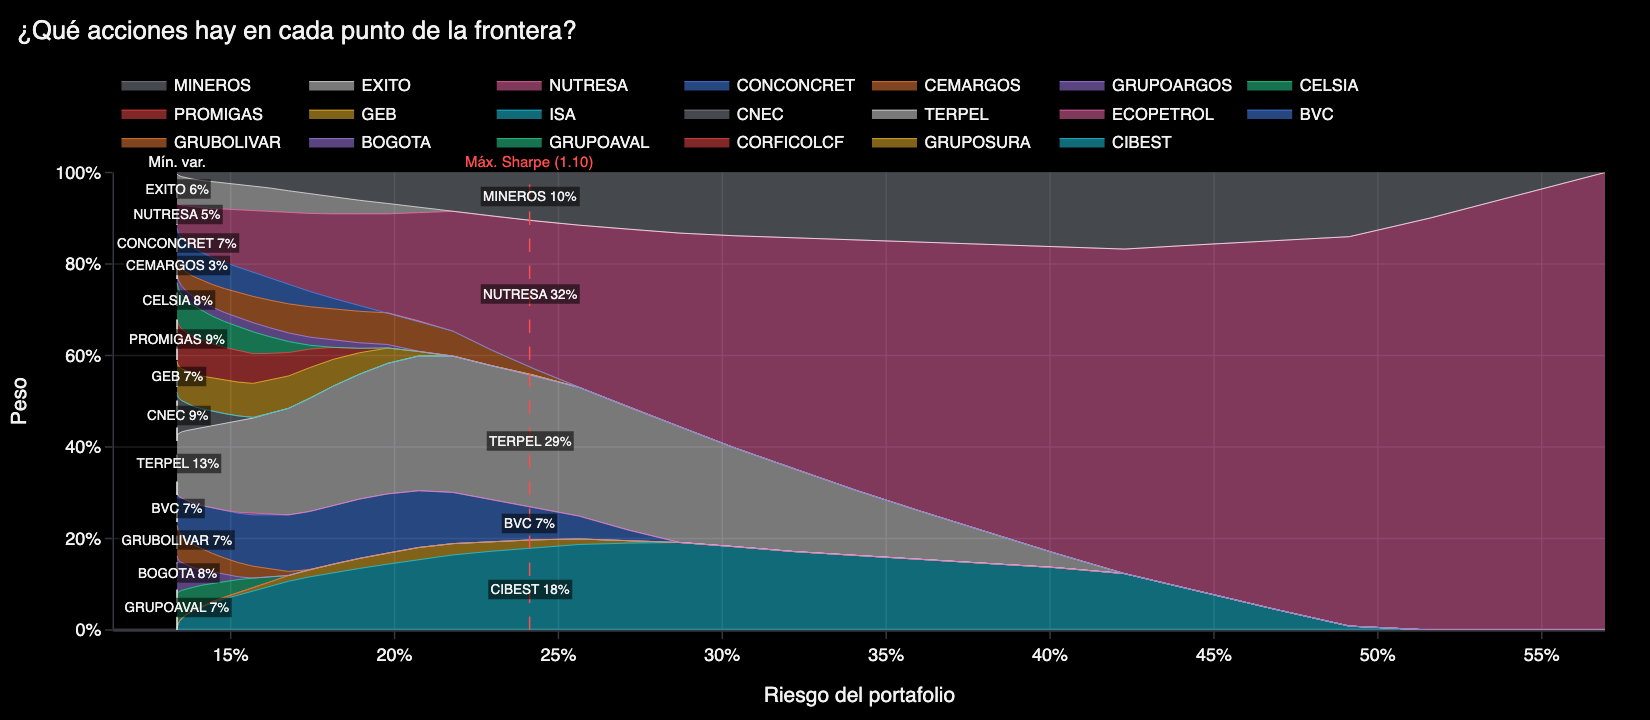

Mejor Sharpe de los portafolios al azar: 0.988
Sharpe que encontró el optimizador: 1.096


In [18]:
# Gráfica: qué acciones hay en cada punto de la frontera eficiente
fig = go.Figure()

for j in range(n):
    fig.add_trace(go.Scatter(x=vol_frontera[eficiente] * 100, y=pesos_frontera[eficiente][:, j] * 100,
                             mode='lines', stackgroup='uno', name=activos[j],
                             line=dict(width=0.5, color=colores[j % len(colores)]),
                             hovertemplate=activos[j] + ': %{y:.0f}%'))

fig.add_vline(x=vol_minvar * 100, line_color=blanco, line_dash='dash', line_width=1,
              annotation=dict(text='Mín. var.', font=dict(color=blanco, size=10)), annotation_position='top')
fig.add_vline(x=vol_sharpe * 100, line_color=rojo, line_dash='dash', line_width=1,
              annotation=dict(text=f'Máx. Sharpe ({sharpe_max:.2f})', font=dict(color=rojo, size=10)),
              annotation_position='top')

# Escribo el peso de cada acción (si pasa de 3%) a la altura de su franja,
# en la línea de la mínima varianza y en la del máximo Sharpe
for punto in [[vol_minvar, w_minvar], [vol_sharpe, w_sharpe]]:
    x_linea = punto[0] * 100
    pesos_punto = punto[1] * 100
    acumulado = 0
    for j in range(n):
        if pesos_punto[j] > 3:
            fig.add_annotation(x=x_linea, y=acumulado + pesos_punto[j] / 2,
                               text=f'{activos[j]} {pesos_punto[j]:.0f}%', showarrow=False,
                               font=dict(size=9, color=blanco), bgcolor='rgba(0,0,0,0.55)')
        acumulado = acumulado + pesos_punto[j]

fig.update_xaxes(title_text='Riesgo del portafolio', ticksuffix='%')
fig.update_yaxes(title_text='Peso', range=[0, 100], ticksuffix='%')
fig.update_layout(title='¿Qué acciones hay en cada punto de la frontera?',
                  height=480, hovermode='x unified')
fig.show()

print("Mejor Sharpe de los portafolios al azar:", round(sharpe_azar.max(), 3))
print("Sharpe que encontró el optimizador:", round(sharpe_max, 3))


## 8. Sharpe, Sortino, Calmar y drawdown



In [19]:
# Retorno diario de cada portafolio con sus pesos
# Con retornos simples: r_p = suma de w_i * r_i
retornos_diarios = pd.DataFrame(index=retornos_portafolio.index)
for i in range(4):
    retornos_diarios[nombres[i]] = serie_portafolio(lista_pesos[i], matriz_retornos)

rf_diaria = rf / 252
tabla_ratios = pd.DataFrame(index=nombres)

for nombre in nombres:
    r = retornos_diarios[nombre]

    retorno_anual_p = r.mean() * 252
    volatilidad_p = r.std() * np.sqrt(252)
    sharpe = (retorno_anual_p - rf) / volatilidad_p

    # Sortino: solo los días por debajo de la rf cuentan como riesgo
    abajo = np.minimum(r - rf_diaria, 0)
    desviacion_abajo = np.sqrt((abajo ** 2).mean()) * np.sqrt(252)
    sortino = (retorno_anual_p - rf) / desviacion_abajo

    # Valor de 1 peso, CAGR y drawdown
    valor = (1 + r).cumprod()
    anios = len(r) / 252
    cagr = valor.iloc[-1] ** (1 / anios) - 1
    drawdown = valor / valor.cummax() - 1
    max_dd = drawdown.min()

    tabla_ratios.loc[nombre, 'Retorno (%)'] = retorno_anual_p * 100
    tabla_ratios.loc[nombre, 'Volatilidad (%)'] = volatilidad_p * 100
    tabla_ratios.loc[nombre, 'Sharpe'] = sharpe
    tabla_ratios.loc[nombre, 'Sortino'] = sortino
    tabla_ratios.loc[nombre, 'CAGR (%)'] = cagr * 100
    tabla_ratios.loc[nombre, 'Máx DD (%)'] = max_dd * 100
    tabla_ratios.loc[nombre, 'Calmar'] = cagr / abs(max_dd)
    tabla_ratios.loc[nombre, 'Asimetría'] = stats.skew(r)
    tabla_ratios.loc[nombre, 'Curtosis exc.'] = stats.kurtosis(r)

print(tabla_ratios.round(2))

                    Retorno (%)  Volatilidad (%)  Sharpe  Sortino  CAGR (%)  Máx DD (%)  Calmar  Asimetría  Curtosis exc.
Equiponderado             14.33            14.94    0.14     0.21     14.13      -28.38    0.50       1.33          23.71
Mínima Varianza           10.78            13.36   -0.11    -0.16     10.39      -30.80    0.34       0.70           8.18
Máximo Sharpe             38.69            24.12    1.10     1.91     43.10      -23.16    1.86       2.94          40.10
Sharpe Restringido        33.17            22.50    0.93     1.62     35.92      -25.14    1.43       3.37          49.04


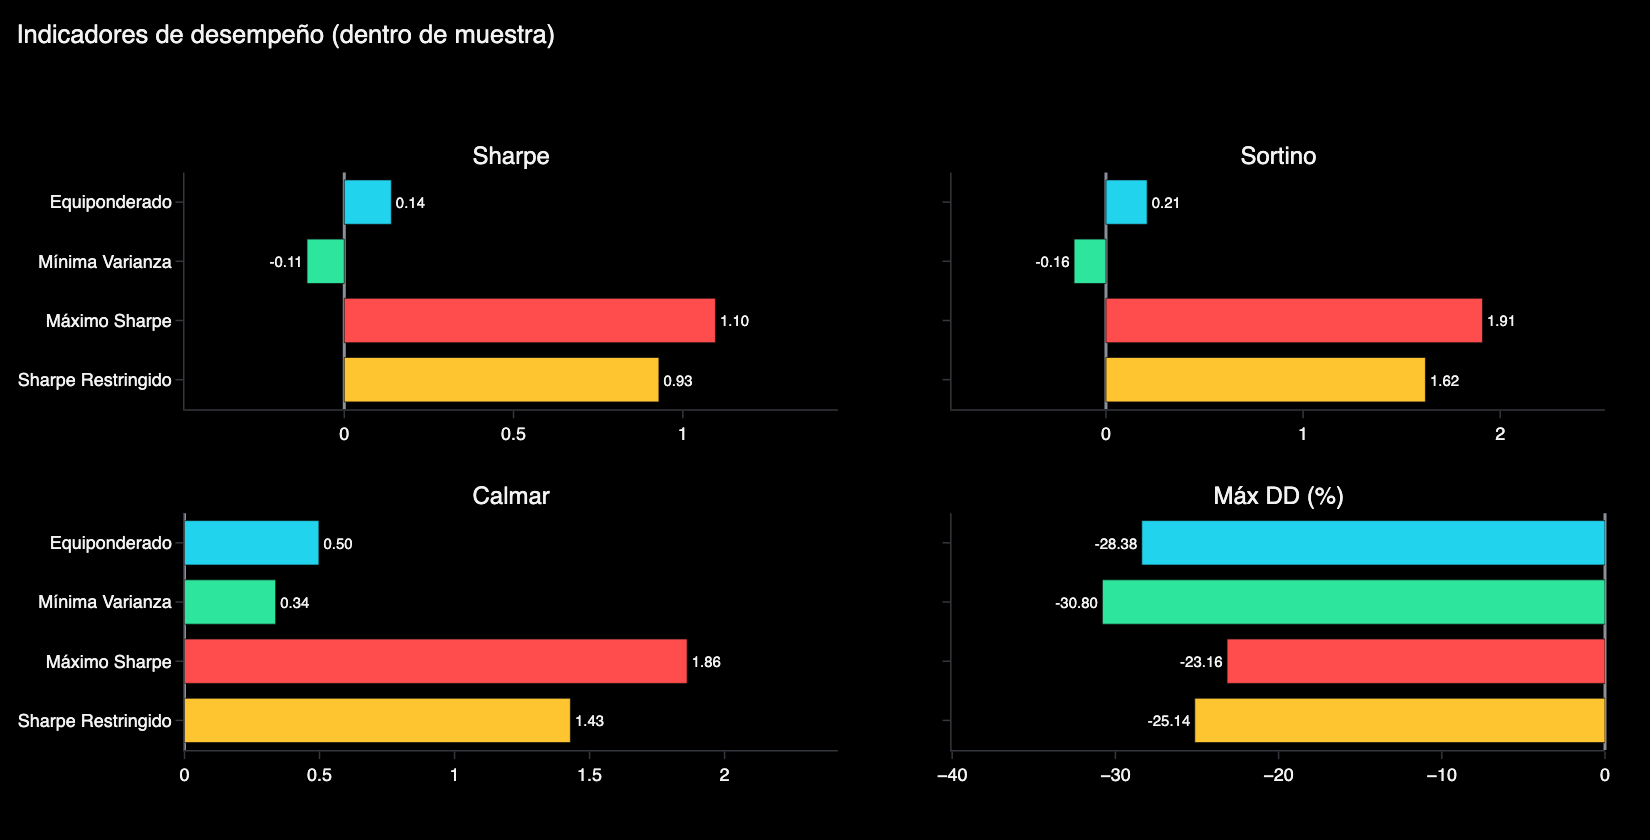

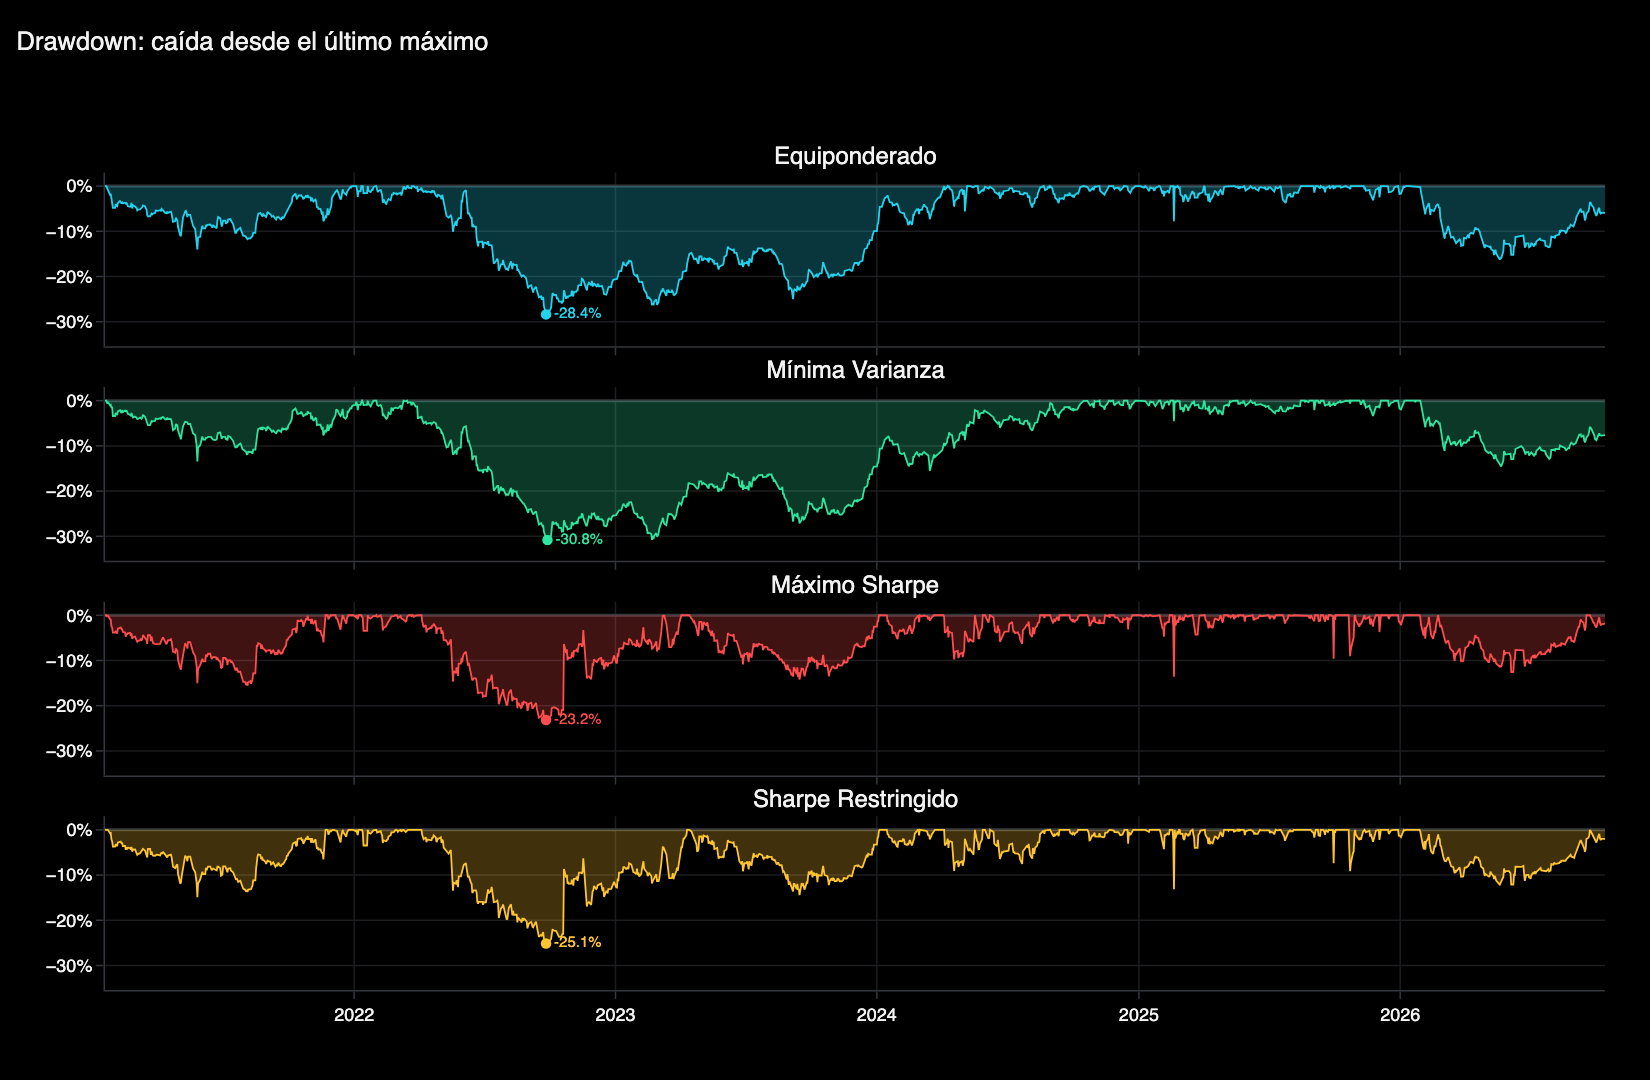

Peor caída de cada portafolio:
  Equiponderado : -28.4 % el 2022-09-26
  Mínima Varianza : -30.8 % el 2022-09-28
  Máximo Sharpe : -23.2 % el 2022-09-26
  Sharpe Restringido : -25.1 % el 2022-09-26


In [20]:
# Gráfica 1: cuatro indicadores (2 filas x 2 columnas)
indicadores = ['Sharpe', 'Sortino', 'Calmar', 'Máx DD (%)']

fig = make_subplots(rows=2, cols=2, subplot_titles=indicadores, shared_yaxes=True,
                    horizontal_spacing=0.08, vertical_spacing=0.18)

for j in range(4):
    valores = tabla_ratios[indicadores[j]]

    # Posición del panel: 0 -> (1,1), 1 -> (1,2), 2 -> (2,1), 3 -> (2,2)
    fila = j // 2 + 1
    columna = j % 2 + 1

    textos = []
    for v in valores:
        textos.append(f'{v:.2f}')

    fig.add_trace(go.Bar(y=nombres, x=valores, orientation='h', marker_color=colores_port,
                         text=textos, textposition='outside', textfont=dict(size=10), cliponaxis=False,
                         showlegend=False, hovertemplate='%{y}: %{x:.2f}'),
                  row=fila, col=columna)

    # Dejo espacio para que el número quepa al lado de la barra
    minimo = min(valores.min(), 0)
    maximo = max(valores.max(), 0)
    margen = (maximo - minimo) * 0.3
    if minimo < 0:
        minimo = minimo - margen
    if maximo > 0:
        maximo = maximo + margen
    fig.update_xaxes(range=[minimo, maximo], zeroline=True, zerolinecolor=gris, showgrid=False,
                     row=fila, col=columna)

fig.update_yaxes(autorange='reversed', showgrid=False)
fig.update_layout(title='Indicadores de desempeño (dentro de muestra)', height=560)
fig.show()

# Gráfica 2: drawdown, un panel por portafolio
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05, subplot_titles=nombres)

for i in range(4):
    valor = (1 + retornos_diarios[nombres[i]]).cumprod()
    drawdown = (valor / valor.cummax() - 1) * 100

    # Mismo color del portafolio, pero transparente para el relleno
    color = colores_port[i]
    relleno = f'rgba({int(color[1:3], 16)}, {int(color[3:5], 16)}, {int(color[5:7], 16)}, 0.25)'

    fig.add_trace(go.Scatter(x=drawdown.index, y=drawdown, mode='lines', fill='tozeroy', fillcolor=relleno,
                             name=nombres[i], line=dict(color=color, width=1.2), showlegend=False,
                             hovertemplate='%{x|%Y-%m-%d}: %{y:.1f}%'),
                  row=i + 1, col=1)

    # Marco el punto más bajo
    fecha_fondo = drawdown.idxmin()
    fig.add_trace(go.Scatter(x=[fecha_fondo], y=[drawdown.min()], mode='markers+text',
                             text=[f'{drawdown.min():.1f}%'], textposition='middle right',
                             textfont=dict(size=10, color=color), marker=dict(color=color, size=7),
                             showlegend=False, hoverinfo='skip'),
                  row=i + 1, col=1)

    fig.update_yaxes(range=[tabla_ratios['Máx DD (%)'].min() * 1.15, 3], ticksuffix='%', row=i + 1, col=1)

fig.update_layout(title='Drawdown: caída desde el último máximo', height=720)
fig.write_image(carpeta + '/drawdown.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()

print("Peor caída de cada portafolio:")
for nombre in nombres:
    valor = (1 + retornos_diarios[nombre]).cumprod()
    fecha_fondo = (valor / valor.cummax() - 1).idxmin()
    print(" ", nombre, ":", round(tabla_ratios.loc[nombre, 'Máx DD (%)'], 1), "% el", fecha_fondo.date())

## 9. VaR y CVaR

- **VaR 95%:** la pérdida diaria que solo se supera el 5% de los días.
- **CVaR 95%:** la pérdida **promedio** en ese 5% de días malos.


**Para las conclusiones uso solo el Monte Carlo t-Student.** 

In [21]:
# Escojo los grados de libertad de la t con los datos (máxima verosimilitud con scipy)

# Paso 1: paso los retornos de cada portafolio a choques: (retorno - media) / desviación
choques_reales = {}
for nombre in nombres:
    r = retornos_diarios[nombre]
    choques_reales[nombre] = (r - r.mean()) / r.std()

# Paso 2: log-verosimilitud de cada candidato, por portafolio y en total
tabla_gl = pd.DataFrame(index=list(gl_candidatos))

for v in gl_candidatos:
    # Escala para que la t tenga varianza 1 (igual que los choques que simulo)
    escala_v = np.sqrt((v - 2) / v)

    total = 0
    for nombre in nombres:
        log_vero = stats.t.logpdf(choques_reales[nombre], v, scale=escala_v).sum()
        tabla_gl.loc[v, nombre] = log_vero
        total = total + log_vero
    tabla_gl.loc[v, 'Total'] = total

# Paso 3: el candidato con la log-verosimilitud total más alta
grados_libertad = int(tabla_gl['Total'].idxmax())

# Lo que habría escogido cada portafolio por separado (para comparar)
print("Grados de libertad que escogería cada portafolio solo:")
for nombre in nombres:
    print(" ", nombre, ":", int(tabla_gl[nombre].idxmax()))

print()
print("Los 5 mejores candidatos (log-verosimilitud total):")
print(tabla_gl['Total'].sort_values(ascending=False).head(5).round(1).to_string())

print()
print("Grados de libertad que uso:", grados_libertad)
if grados_libertad == max(gl_candidatos):
    print("Ojo: quedó en el máximo de los candidatos, las colas casi no son gordas (se parece a la normal).")
if grados_libertad == min(gl_candidatos):
    print("Ojo: quedó en el mínimo de los candidatos, las colas son muy gordas.")

Grados de libertad que escogería cada portafolio solo:
  Equiponderado : 3
  Mínima Varianza : 4
  Máximo Sharpe : 3
  Sharpe Restringido : 3

Los 5 mejores candidatos (log-verosimilitud total):
3   -6867.7
4   -6973.4
5   -7066.7
6   -7136.4
7   -7190.5

Grados de libertad que uso: 3
Ojo: quedó en el mínimo de los candidatos, las colas son muy gordas.


In [22]:
# Choques simulados UNA sola vez, iguales para los cuatro portafolios
choques_normal = np.random.normal(0, 1, n_sim)

# La t-Student la divido para que tenga varianza 1, igual que la normal
choques_t = np.random.standard_t(grados_libertad, n_sim)
choques_t = choques_t / np.sqrt(grados_libertad / (grados_libertad - 2))

tabla_var = pd.DataFrame(index=nombres)
tabla_cvar = pd.DataFrame(index=nombres)

for nombre in nombres:
    r = retornos_diarios[nombre]
    media = r.mean()
    sigma = r.std()

    # Retornos simulados de este portafolio = media + desviación x choque
    sim_normal = media + sigma * choques_normal
    sim_t = media + sigma * choques_t

    for confianza in [0.95, 0.99]:
        alpha = 1 - confianza
        nivel = str(int(confianza * 100)) + '%'

        # 1. Histórico
        var_h = np.percentile(r, alpha * 100)
        cvar_h = r[r <= var_h].mean()

        # 2. Paramétrico (normal)
        z = stats.norm.ppf(alpha)
        var_p = media + z * sigma
        cvar_p = media - sigma * stats.norm.pdf(z) / alpha

        # 3. Monte Carlo normal
        var_mc = np.percentile(sim_normal, alpha * 100)
        cvar_mc = sim_normal[sim_normal <= var_mc].mean()

        # 4. Monte Carlo t-Student (el que uso en las conclusiones)
        var_t = np.percentile(sim_t, alpha * 100)
        cvar_t = sim_t[sim_t <= var_t].mean()

        # Guardo las pérdidas como números positivos
        tabla_var.loc[nombre, 'Hist ' + nivel] = -var_h
        tabla_var.loc[nombre, 'Param ' + nivel] = -var_p
        tabla_var.loc[nombre, 'MC ' + nivel] = -var_mc
        tabla_var.loc[nombre, 'MC t ' + nivel] = -var_t

        tabla_cvar.loc[nombre, 'Hist ' + nivel] = -cvar_h
        tabla_cvar.loc[nombre, 'Param ' + nivel] = -cvar_p
        tabla_cvar.loc[nombre, 'MC ' + nivel] = -cvar_mc
        tabla_cvar.loc[nombre, 'MC t ' + nivel] = -cvar_t

print("VaR diario (% de pérdida):")
print((tabla_var * 100).round(2))
print()
print("CVaR diario (% de pérdida):")
print((tabla_cvar * 100).round(2))

print()
print("VaR Monte Carlo t en pesos, sobre un capital de", f"{capital:,.0f}", "COP:")
for nombre in nombres:
    print(" ", nombre, "| 99%:", f"{tabla_var.loc[nombre, 'MC t 99%'] * capital:,.0f}",
          "| 99%:", f"{tabla_var.loc[nombre, 'MC t 99%'] * capital:,.0f}")

var_99 = tabla_var.loc['Máximo Sharpe', 'MC t 99%']
cvar_99 = tabla_cvar.loc['Máximo Sharpe', 'MC t 99%']
print()
print("Máximo Sharpe (Monte Carlo t): 99 de cada 100 días no debería perder más de", round(var_99 * 100, 2), "%")
print("Pero el día que lo supera, pierde en promedio", round(cvar_99 * 100, 2), "%")

VaR diario (% de pérdida):
                    Hist 95%  Param 95%  MC 95%  MC t 95%  Hist 99%  Param 99%  MC 99%  MC t 99%
Equiponderado           1.31       1.49    1.49      1.21      2.40       2.13    2.13      2.39
Mínima Varianza         1.20       1.34    1.34      1.09      2.08       1.92    1.91      2.14
Máximo Sharpe           1.69       2.35    2.35      1.90      2.86       3.38    3.38      3.79
Sharpe Restringido      1.58       2.20    2.20      1.78      2.75       3.17    3.16      3.55

CVaR diario (% de pérdida):
                    Hist 95%  Param 95%  MC 95%  MC t 95%  Hist 99%  Param 99%  MC 99%  MC t 99%
Equiponderado           1.98       1.88    1.89      2.03      3.17       2.45    2.46      3.70
Mínima Varianza         1.82       1.69    1.69      1.82      2.71       2.20    2.20      3.31
Máximo Sharpe           2.73       2.98    2.98      3.21      5.04       3.90    3.90      5.90
Sharpe Restringido      2.56       2.79    2.79      3.01      4.76    

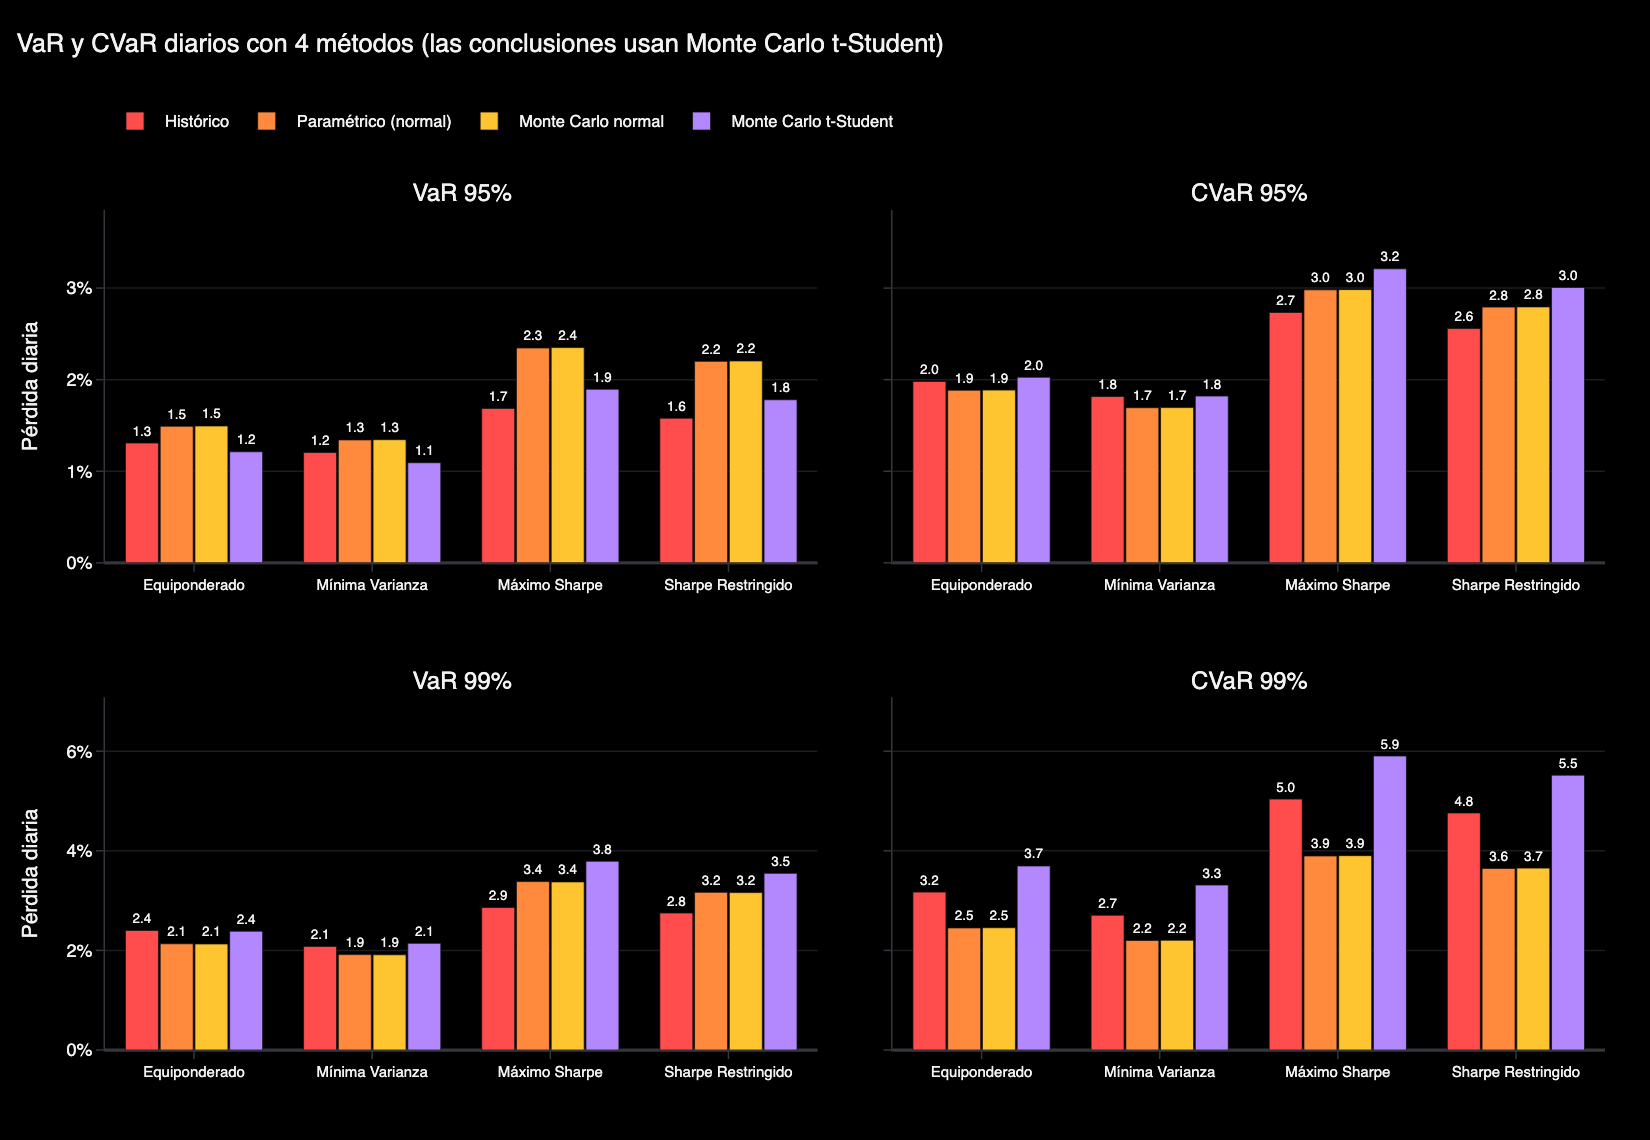

In [23]:
# Gráfica 1: los 4 métodos lado a lado
metodos = ['Hist', 'Param', 'MC', 'MC t']
nombres_metodos = ['Histórico', 'Paramétrico (normal)', 'Monte Carlo normal', 'Monte Carlo t-Student']
colores_metodos = [rojo, naranja, dorado, morado]

fig = make_subplots(rows=2, cols=2, shared_yaxes='rows', vertical_spacing=0.16, horizontal_spacing=0.05,
                    subplot_titles=['VaR 95%', 'CVaR 95%', 'VaR 99%', 'CVaR 99%'])

# Dónde va cada panel: [fila, columna, tabla, nivel]
# Fila 1: 95%  |  Fila 2: 99%  |  Columna 1: VaR  |  Columna 2: CVaR
paneles = [[1, 1, tabla_var, '95%'],
           [1, 2, tabla_cvar, '95%'],
           [2, 1, tabla_var, '99%'],
           [2, 2, tabla_cvar, '99%']]

for k in range(4):
    m = metodos[k]

    for panel in paneles:
        fila = panel[0]
        columna = panel[1]
        tabla = panel[2]
        nivel = panel[3]

        valores = tabla[m + ' ' + nivel] * 100

        textos = []
        for v in valores:
            textos.append(f'{v:.1f}')

        fig.add_trace(go.Bar(x=nombres, y=valores, name=nombres_metodos[k], marker_color=colores_metodos[k],
                             text=textos, textposition='outside', textfont=dict(size=9), cliponaxis=False,
                             legendgroup=m, showlegend=(fila == 1 and columna == 1),
                             hovertemplate=nombres_metodos[k] + ' | %{x}: %{y:.2f}%'),
                      row=fila, col=columna)

# Mismo techo para las dos gráficas de cada fila
maximo_95 = max(tabla_var.filter(like='95%').max().max(), tabla_cvar.filter(like='95%').max().max()) * 100
maximo_99 = max(tabla_var.filter(like='99%').max().max(), tabla_cvar.filter(like='99%').max().max()) * 100
fig.update_yaxes(range=[0, maximo_95 * 1.2], ticksuffix='%', row=1)
fig.update_yaxes(range=[0, maximo_99 * 1.2], ticksuffix='%', row=2)
fig.update_yaxes(title_text='Pérdida diaria', col=1)
fig.update_xaxes(tickfont=dict(size=10), showgrid=False)
fig.update_layout(title='VaR y CVaR diarios con 4 métodos (las conclusiones usan Monte Carlo t-Student)',
                  barmode='group', height=760, bargap=0.22, bargroupgap=0.05,
                  legend=dict(y=1.08), margin=dict(t=140))
fig.show()

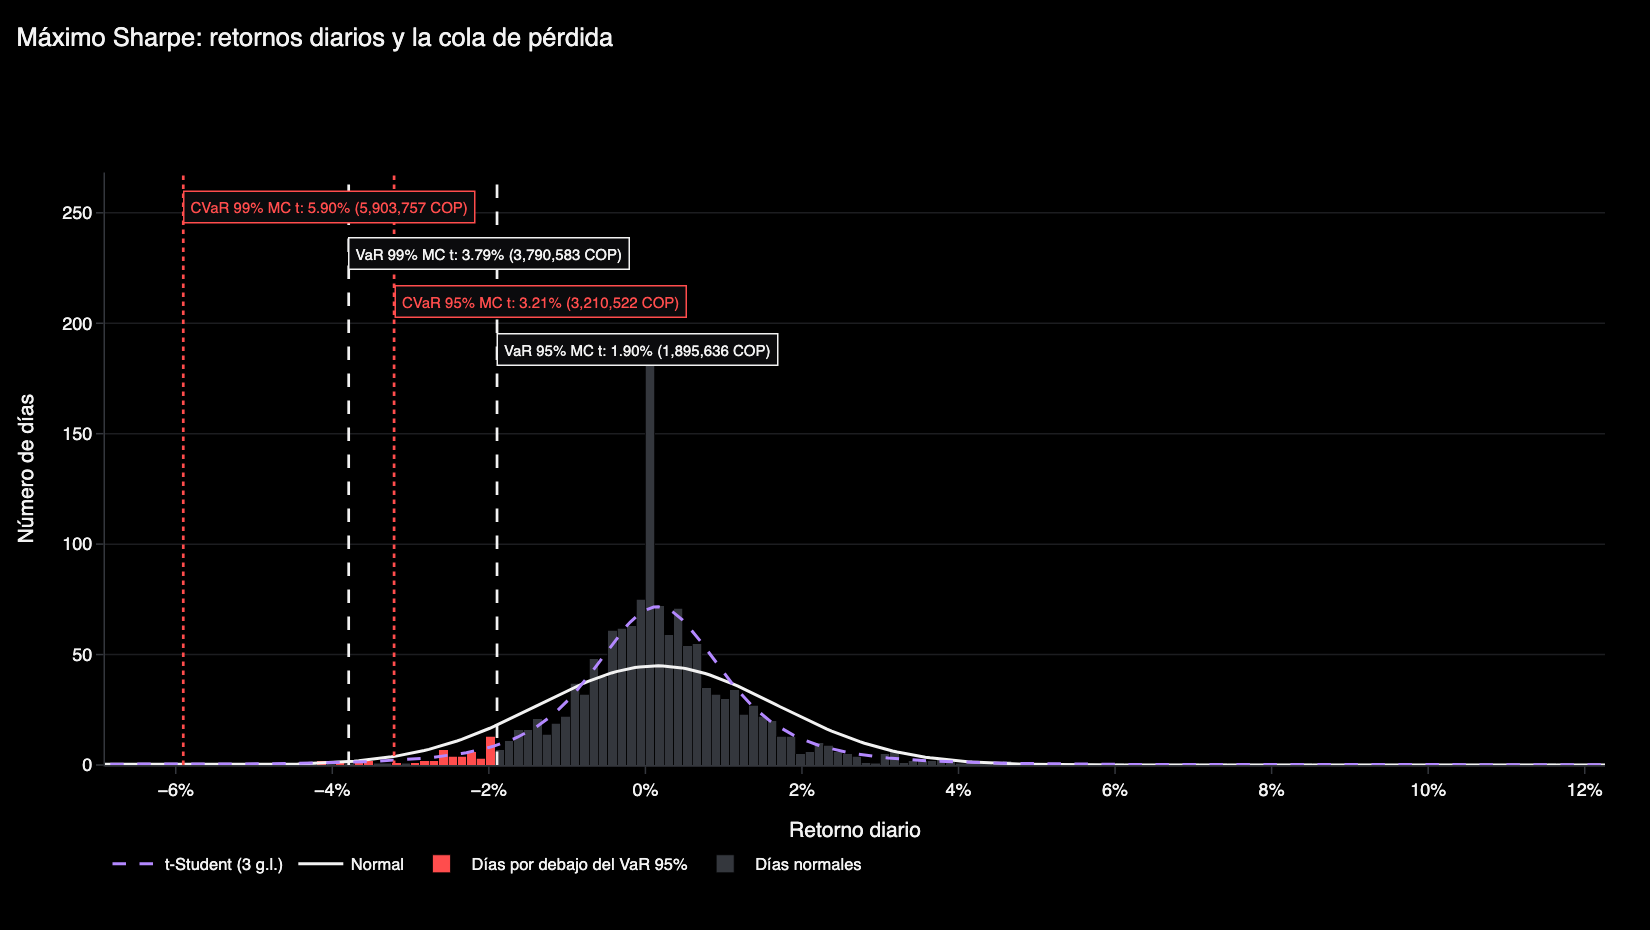

Barras rojas: 55 de 1425 días
Peor día del periodo: -11.32 % el 2025-02-19


In [24]:
# Gráfica 2: distribución de los retornos con la cola de pérdida
portafolio_var = 'Máximo Sharpe'     # cámbialo para ver otro portafolio

r = retornos_diarios[portafolio_var] * 100
media = r.mean()
sigma = r.std()
escala_t = sigma / np.sqrt(grados_libertad / (grados_libertad - 2))

var_95 = -tabla_var.loc[portafolio_var, 'MC t 95%'] * 100
cvar_95 = -tabla_cvar.loc[portafolio_var, 'MC t 95%'] * 100
var_99 = -tabla_var.loc[portafolio_var, 'MC t 99%'] * 100
cvar_99 = -tabla_cvar.loc[portafolio_var, 'MC t 99%'] * 100

# Separo los días: los peores (cola) y el resto
dias_cola = r[r <= var_95]
dias_normales = r[r > var_95]

# Ancho de cada barra: unas 80 barras entre el percentil 0.5 y el 99.5
ancho_barra = round((r.quantile(0.995) - r.quantile(0.005)) / 80, 2)
ancho_barra = max(ancho_barra, 0.05)
inicio_barras = np.floor(r.min() / ancho_barra) * ancho_barra
x = np.linspace(r.min(), r.max(), 500)

# Curvas teóricas: la densidad por (número de días x ancho de barra) para que quede en "días"
escala = len(r) * ancho_barra
curva_normal = stats.norm.pdf(x, media, sigma) * escala
curva_t = stats.t.pdf((x - media) / escala_t, grados_libertad) / escala_t * escala

# Altura de la barra más alta, para dejar espacio arriba para los cuadros
bordes = np.arange(inicio_barras, r.max() + 2 * ancho_barra, ancho_barra)
conteo, bordes = np.histogram(r, bins=bordes)
y_maximo = max(conteo.max(), curva_normal.max(), curva_t.max())

fig = go.Figure()

# Histograma en número de días: días normales en gris y días de la cola en rojo
fig.add_trace(go.Histogram(x=dias_normales, name='Días normales',
                           xbins=dict(start=inicio_barras, end=r.max() + ancho_barra, size=ancho_barra),
                           marker=dict(color=gris_oscuro, line=dict(color=negro, width=0.5))))
fig.add_trace(go.Histogram(x=dias_cola, name='Días por debajo del VaR 95%',
                           xbins=dict(start=inicio_barras, end=r.max() + ancho_barra, size=ancho_barra),
                           marker=dict(color=rojo, line=dict(color=negro, width=0.5))))

fig.add_trace(go.Scatter(x=x, y=curva_normal, mode='lines', name='Normal', line=dict(color=blanco, width=2)))
fig.add_trace(go.Scatter(x=x, y=curva_t, mode='lines', name=f't-Student ({grados_libertad} g.l.)',
                         line=dict(color=morado, width=2, dash='dash')))

lineas = [[cvar_99, 'CVaR 99%', rojo, 'dot', 0.97],
          [var_99, 'VaR 99%', blanco, 'dash', 0.89],
          [cvar_95, 'CVaR 95%', rojo, 'dot', 0.81],
          [var_95, 'VaR 95%', blanco, 'dash', 0.73]]

for linea in lineas:
    valor = linea[0]
    nombre = linea[1]
    color = linea[2]

    fig.add_vline(x=valor, line_color=color, line_dash=linea[3], line_width=1.8)
    fig.add_annotation(x=valor, y=linea[4], yref='paper', xanchor='left', showarrow=False,
                       text=f'{nombre} MC t: {-valor:.2f}% ({-valor / 100 * capital:,.0f} COP)',
                       font=dict(size=10, color=color), bgcolor=fondo_caja, bordercolor=color, borderpad=4)

# Eje x: del CVaR 99% (con un poco de espacio) al percentil 99.8 por la derecha
limite_izquierdo = min(r.quantile(0.002), cvar_99) - 1
fig.update_xaxes(title_text='Retorno diario', ticksuffix='%', range=[limite_izquierdo, r.quantile(0.998)])
# Eje y: 45% más alto que la barra más alta, para que los cuadros no tapen las barras
fig.update_yaxes(title_text='Número de días', range=[0, y_maximo * 1.45])
fig.update_layout(title=f'{portafolio_var}: retornos diarios y la cola de pérdida',
                  barmode='stack', bargap=0, height=620,
                  legend=dict(orientation='h', yanchor='top', y=-0.13, x=0), margin=dict(b=110))
fig.write_image(carpeta + '/var_cvar.png', scale=2, width=ancho_imagen, height=620)   # imagen para el README
fig.show()

print("Barras rojas:", len(dias_cola), "de", len(r), "días")
print("Peor día del periodo:", round(r.min(), 2), "% el", r.idxmin().date())


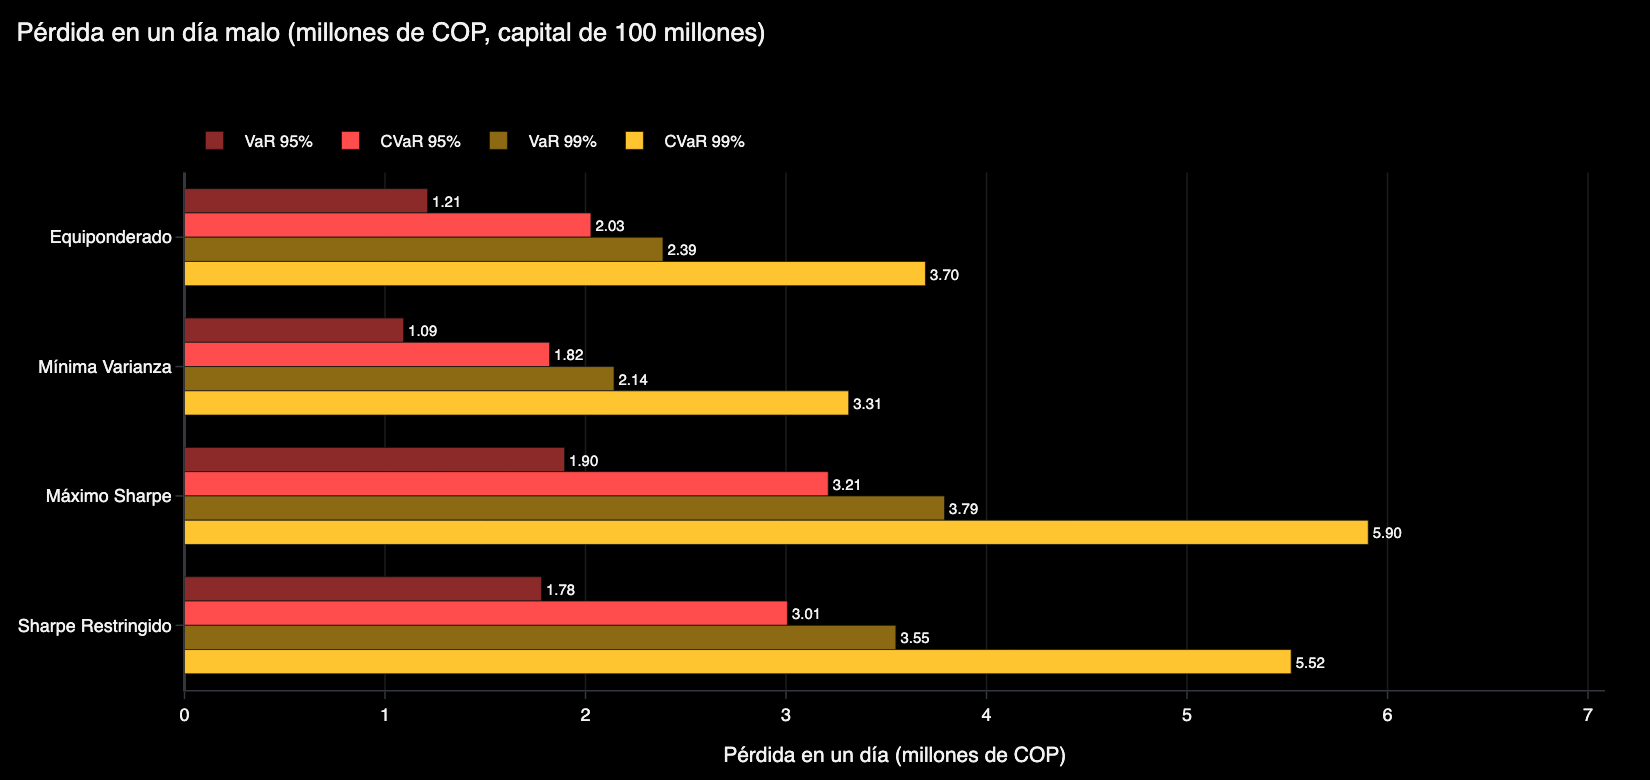

Menos riesgo diario: Mínima Varianza con un VaR 99% de 2.14 millones
Más riesgo diario: Máximo Sharpe con un VaR 99% de 3.79 millones
Más riesgo CVAR diario: Máximo Sharpe con un CVaR 99% de 5.9 millones


In [25]:
# Gráfica 3: VaR y CVaR en millones de pesos (método Monte Carlo t-Student)
var_pesos_95 = tabla_var['MC t 95%'] * capital / 1000000
cvar_pesos_95 = tabla_cvar['MC t 95%'] * capital / 1000000
var_pesos_99 = tabla_var['MC t 99%'] * capital / 1000000
cvar_pesos_99 = tabla_cvar['MC t 99%'] * capital / 1000000

fig = go.Figure()

# Cada barra: [valores, nombre, color]
barras = [[var_pesos_95, 'VaR 95%', '#8C2A2A'],
          [cvar_pesos_95, 'CVaR 95%', rojo],
          [var_pesos_99, 'VaR 99%', '#8C6A14'],
          [cvar_pesos_99, 'CVaR 99%', dorado]]

for barra in barras:
    valores = barra[0]
    textos = []
    for v in valores:
        textos.append(f'{v:.2f}')

    fig.add_trace(go.Bar(y=nombres, x=valores, orientation='h', name=barra[1], marker_color=barra[2],
                         text=textos, textposition='outside', textfont=dict(size=10), cliponaxis=False,
                         hovertemplate='%{y}: %{x:.2f} millones (' + barra[1] + ')'))

fig.update_xaxes(title_text='Pérdida en un día (millones de COP)', range=[0, cvar_pesos_99.max() * 1.2])
fig.update_yaxes(autorange='reversed', showgrid=False)
fig.update_layout(title=f'Pérdida en un día malo (millones de COP, capital de {capital / 1000000:,.0f} millones)',
                  barmode='group', height=520, bargap=0.25)
fig.show()

print("Menos riesgo diario:", var_pesos_99.idxmin(), "con un VaR 99% de", round(var_pesos_99.min(), 2), "millones")
print("Más riesgo diario:", var_pesos_99.idxmax(), "con un VaR 99% de", round(var_pesos_99.max(), 2), "millones")
print("Más riesgo CVAR diario:", cvar_pesos_99.idxmax(), "con un CVaR 99% de", round(cvar_pesos_99.max(), 2), "millones")



## 10. Backtesting de los 4 métodos de VaR



In [26]:
minimo_dias = 250    # un año de historia antes de empezar a evaluar
eps = 1e-10          # número muy pequeño para no sacar logaritmo de 0

metodos = ['Hist', 'Param', 'MC', 'MC t']
filas = []

for nombre in nombres:
    r = retornos_diarios[nombre]

    # Media y desviación de cada día con todos los días ANTERIORES (shift(1) = no uso el día de hoy)
    media_dia = r.expanding(min_periods=minimo_dias).mean().shift(1)
    sigma_dia = r.expanding(min_periods=minimo_dias).std().shift(1)

    for confianza in [0.95, 0.99]:
        p = 1 - confianza

        for metodo in metodos:
            # VaR de cada día con el método que toca
            if metodo == 'Hist':
                var_dia = r.expanding(min_periods=minimo_dias).quantile(p).shift(1)
            elif metodo == 'Param':
                var_dia = media_dia + sigma_dia * stats.norm.ppf(p)
            elif metodo == 'MC':
                var_dia = media_dia + sigma_dia * np.percentile(choques_normal, p * 100)
            else:
                var_dia = media_dia + sigma_dia * np.percentile(choques_t, p * 100)

            evaluacion = pd.DataFrame({'retorno': r, 'var': var_dia}).dropna()
            evaluacion['violacion'] = evaluacion['retorno'] < evaluacion['var']

            T = len(evaluacion)
            N = evaluacion['violacion'].sum()
            p_obs = N / T

            # Kupiec
            log_esperada = (T - N) * np.log(1 - p) + N * np.log(p)
            log_observada = (T - N) * np.log(max(1 - p_obs, eps)) + N * np.log(max(p_obs, eps))
            LR_kupiec = -2 * (log_esperada - log_observada)
            p_kupiec = 1 - stats.chi2.cdf(LR_kupiec, df=1)

            # Christoffersen: cuento qué pasa el día después de cada día
            violaciones = evaluacion['violacion'].astype(int).values
            n00 = 0   # normal -> normal
            n01 = 0   # normal -> violación
            n10 = 0   # violación -> normal
            n11 = 0   # violación -> violación
            for t in range(1, T):
                ayer = violaciones[t - 1]
                hoy = violaciones[t]
                if ayer == 0 and hoy == 0:
                    n00 = n00 + 1
                elif ayer == 0 and hoy == 1:
                    n01 = n01 + 1
                elif ayer == 1 and hoy == 0:
                    n10 = n10 + 1
                else:
                    n11 = n11 + 1

            pi0 = n01 / max(n00 + n01, 1)                 # prob. de violación después de un día normal
            pi1 = n11 / max(n10 + n11, 1)                 # prob. de violación después de una violación
            pi = (n01 + n11) / (n00 + n01 + n10 + n11)    # prob. de violación en general

            # Si alguna vale 0 o 1, la acoto para que el logaritmo no explote
            pi0 = min(max(pi0, eps), 1 - eps)
            pi1 = min(max(pi1, eps), 1 - eps)
            pi = min(max(pi, eps), 1 - eps)

            log_independiente = (n00 + n10) * np.log(1 - pi) + (n01 + n11) * np.log(pi)
            log_rachas = (n00 * np.log(1 - pi0) + n01 * np.log(pi0)
                          + n10 * np.log(1 - pi1) + n11 * np.log(pi1))
            LR_christ = -2 * (log_independiente - log_rachas)
            p_christ = 1 - stats.chi2.cdf(LR_christ, df=1)

            if p_kupiec > 0.05:
                cantidad_ok = 'sí'
            else:
                cantidad_ok = 'NO'

            if p_christ > 0.05:
                sin_rachas = 'sí'
            else:
                sin_rachas = 'NO'

            filas.append([nombre, metodo, str(int(confianza * 100)) + '%', T, N, round(p * T, 1),
                          round(p_obs * 100, 2), round(p_kupiec, 4), round(p_christ, 4),
                          cantidad_ok, sin_rachas])

tabla_backtest = pd.DataFrame(filas, columns=['Portafolio', 'Método', 'Nivel', 'Días', 'Violaciones', 'Esperadas',
                                              'Tasa (%)', 'p Kupiec', 'p Christoffersen',
                                              'Cantidad OK', 'Sin rachas'])
print(tabla_backtest.to_string(index=False))

# Resumen: cuántos casos pasa cada método (8 casos = 4 portafolios x 2 niveles)
print()
print("Casos que pasa cada método (de", len(nombres) * 2, "):")
for metodo in metodos:
    casos = tabla_backtest[tabla_backtest['Método'] == metodo]
    pasa_kupiec = (casos['Cantidad OK'] == 'sí').sum()
    pasa_christ = (casos['Sin rachas'] == 'sí').sum()
    print(" ", metodo, "| Kupiec:", pasa_kupiec, "| Christoffersen:", pasa_christ)

# Para las conclusiones me quedo con el Monte Carlo t
backtest_mct = tabla_backtest[tabla_backtest['Método'] == 'MC t']
print()
print("Monte Carlo t: casos que fallan Kupiec (cantidad de violaciones):", (backtest_mct['Cantidad OK'] == 'NO').sum())
print("Monte Carlo t: casos que fallan Christoffersen (rachas):", (backtest_mct['Sin rachas'] == 'NO').sum())

        Portafolio Método Nivel  Días  Violaciones  Esperadas  Tasa (%)  p Kupiec  p Christoffersen Cantidad OK Sin rachas
     Equiponderado   Hist   95%  1175           56       58.8      4.77    0.7107            0.0046          sí         NO
     Equiponderado  Param   95%  1175           46       58.8      3.91    0.0765            0.1372          sí         sí
     Equiponderado     MC   95%  1175           46       58.8      3.91    0.0765            0.1372          sí         sí
     Equiponderado   MC t   95%  1175           72       58.8      6.13    0.0862            0.0380          sí         NO
     Equiponderado   Hist   99%  1175           13       11.8      1.11    0.7186            0.5895          sí         sí
     Equiponderado  Param   99%  1175           21       11.8      1.79    0.0146            0.3871          NO         sí
     Equiponderado     MC   99%  1175           21       11.8      1.79    0.0146            0.3871          NO         sí
     Equipondera

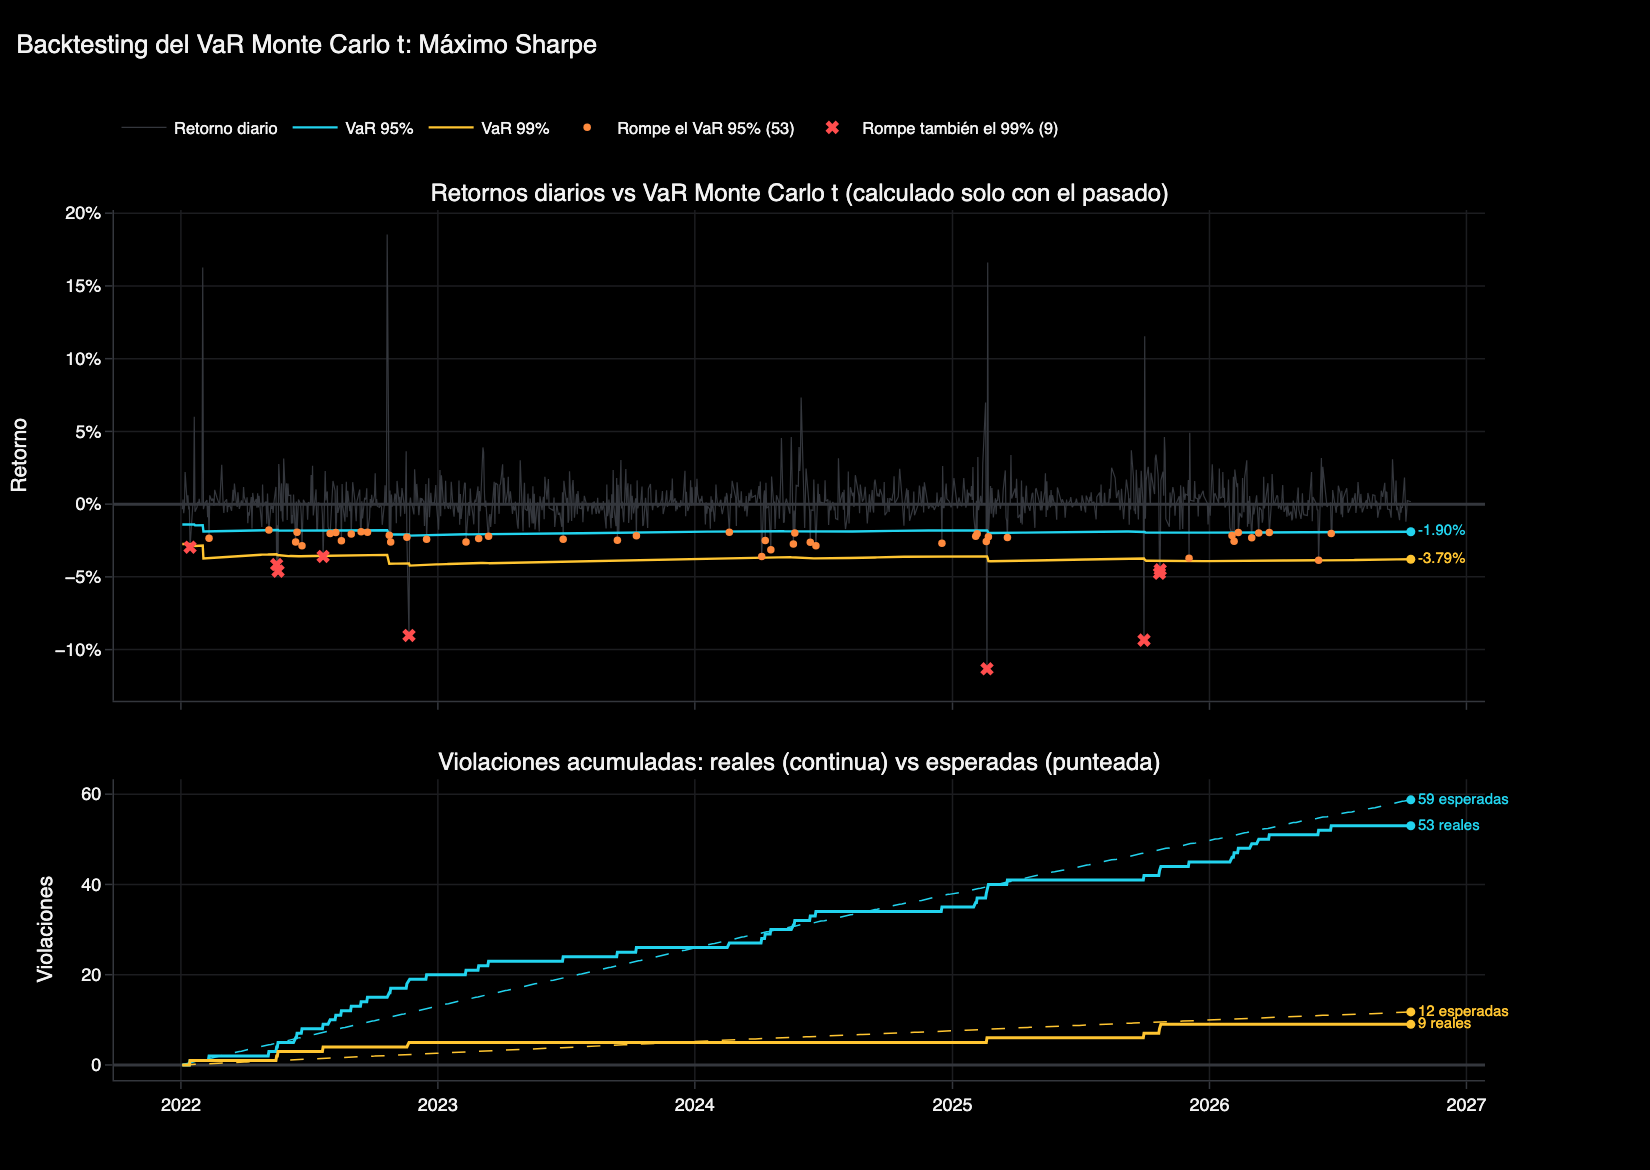

In [27]:
# Gráfica: backtest del portafolio elegido arriba (portafolio_var)
r = retornos_diarios[portafolio_var]

# VaR Monte Carlo t de cada día (el de las conclusiones), con la media y desviación de los días anteriores
media_dia = r.expanding(min_periods=minimo_dias).mean().shift(1)
sigma_dia = r.expanding(min_periods=minimo_dias).std().shift(1)
var_95_dia = media_dia + sigma_dia * np.percentile(choques_t, 5)
var_99_dia = media_dia + sigma_dia * np.percentile(choques_t, 1)

evaluacion = pd.DataFrame({'retorno': r, 'var 95': var_95_dia, 'var 99': var_99_dia}).dropna()
evaluacion['viola 95'] = evaluacion['retorno'] < evaluacion['var 95']
evaluacion['viola 99'] = evaluacion['retorno'] < evaluacion['var 99']

violados_95 = evaluacion[evaluacion['viola 95'] & ~evaluacion['viola 99']]   # solo rompen el 95%
violados_99 = evaluacion[evaluacion['viola 99']]                            # rompen también el 99%

# Violaciones acumuladas: reales vs esperadas (una línea recta)
acumuladas_95 = evaluacion['viola 95'].cumsum()
acumuladas_99 = evaluacion['viola 99'].cumsum()
dias = np.arange(1, len(evaluacion) + 1)

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.62, 0.38], vertical_spacing=0.09,
                    subplot_titles=['Retornos diarios vs VaR Monte Carlo t (calculado solo con el pasado)',
                                    'Violaciones acumuladas: reales (continua) vs esperadas (punteada)'])

# Panel 1: retornos, líneas de VaR y violaciones
fig.add_trace(go.Scatter(x=evaluacion.index, y=evaluacion['retorno'] * 100, mode='lines',
                         name='Retorno diario', line=dict(color=gris_oscuro, width=0.8),
                         hovertemplate='%{x|%Y-%m-%d}: %{y:.2f}%'), row=1, col=1)
fig.add_trace(go.Scatter(x=evaluacion.index, y=evaluacion['var 95'] * 100, mode='lines', name='VaR 95%',
                         line=dict(color=cyan, width=1.6)), row=1, col=1)
fig.add_trace(go.Scatter(x=evaluacion.index, y=evaluacion['var 99'] * 100, mode='lines', name='VaR 99%',
                         line=dict(color=dorado, width=1.6)), row=1, col=1)
fig.add_trace(go.Scatter(x=violados_95.index, y=violados_95['retorno'] * 100, mode='markers',
                         name=f'Rompe el VaR 95% ({int(evaluacion["viola 95"].sum())})',
                         marker=dict(color=naranja, size=5)), row=1, col=1)
fig.add_trace(go.Scatter(x=violados_99.index, y=violados_99['retorno'] * 100, mode='markers',
                         name=f'Rompe también el 99% ({int(evaluacion["viola 99"].sum())})',
                         marker=dict(color=rojo, size=8, symbol='x')), row=1, col=1)

# Panel 2: violaciones acumuladas
fig.add_trace(go.Scatter(x=evaluacion.index, y=acumuladas_95, mode='lines', line=dict(color=cyan, width=2),
                         showlegend=False, hovertemplate='Reales 95%: %{y}'), row=2, col=1)
fig.add_trace(go.Scatter(x=evaluacion.index, y=dias * 0.05, mode='lines',
                         line=dict(color=cyan, width=1, dash='dash'),
                         showlegend=False, hovertemplate='Esperadas 95%: %{y:.0f}'), row=2, col=1)
fig.add_trace(go.Scatter(x=evaluacion.index, y=acumuladas_99, mode='lines', line=dict(color=dorado, width=2),
                         showlegend=False, hovertemplate='Reales 99%: %{y}'), row=2, col=1)
fig.add_trace(go.Scatter(x=evaluacion.index, y=dias * 0.01, mode='lines',
                         line=dict(color=dorado, width=1, dash='dash'),
                         showlegend=False, hovertemplate='Esperadas 99%: %{y:.0f}'), row=2, col=1)

# Valor del último día al final de cada línea
ultimo = evaluacion.index[-1]
finales = [[1, evaluacion['var 95'].iloc[-1] * 100, f"{evaluacion['var 95'].iloc[-1] * 100:.2f}%", cyan],
           [1, evaluacion['var 99'].iloc[-1] * 100, f"{evaluacion['var 99'].iloc[-1] * 100:.2f}%", dorado],
           [2, acumuladas_95.iloc[-1], f'{acumuladas_95.iloc[-1]} reales', cyan],
           [2, dias[-1] * 0.05, f'{dias[-1] * 0.05:.0f} esperadas', cyan],
           [2, acumuladas_99.iloc[-1], f'{acumuladas_99.iloc[-1]} reales', dorado],
           [2, dias[-1] * 0.01, f'{dias[-1] * 0.01:.0f} esperadas', dorado]]
for final in finales:
    fig.add_trace(go.Scatter(x=[ultimo], y=[final[1]], mode='markers+text', text=[final[2]],
                             textposition='middle right', textfont=dict(size=10, color=final[3]),
                             marker=dict(size=6, color=final[3]), cliponaxis=False,
                             showlegend=False, hoverinfo='skip'), row=final[0], col=1)

fig.update_yaxes(title_text='Retorno', ticksuffix='%', row=1, col=1)
fig.update_yaxes(title_text='Violaciones', row=2, col=1)
fig.update_layout(title=f'Backtesting del VaR Monte Carlo t: {portafolio_var}', height=780,
                  legend=dict(y=1.07), margin=dict(t=140, r=110))
fig.write_image(carpeta + '/backtest_var.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()



## 11. Walk-forward: la prueba sin mirar el futuro


In [28]:
ventana_inicial = 252
fechas = retornos_portafolio.index

# Todos arrancan con pesos iguales
w_equi_wf = np.ones(n) / n
w_minvar_wf = np.ones(n) / n
w_sharpe_wf = np.ones(n) / n
w_restric_wf = np.ones(n) / n

# Aquí voy guardando el retorno de cada día
ret_equi_wf = []
ret_minvar_wf = []
ret_sharpe_wf = []
ret_restric_wf = []

# Rotación (cuánto del portafolio compro o vendo) en cada rebalanceo
rot_equi = []
rot_minvar = []
rot_sharpe = []
rot_restric = []


for i in range(ventana_inicial, len(fechas)):

    # ¿Es el primer día del walk-forward o el primer día de un mes nuevo? -> recalculo pesos
    es_primer_dia = (i == ventana_inicial)
    cambio_de_mes = (fechas[i].month != fechas[i - 1].month)

    # Por defecto hoy no pago costos (solo los pago el día que cambio los pesos)
    costo_equi = 0
    costo_minvar = 0
    costo_sharpe = 0
    costo_restric = 0

    if es_primer_dia or cambio_de_mes:
        # Pesos que tenía antes de rebalancear (el primer día no tengo nada: todo es compra)
        if es_primer_dia:
            antes_equi = np.zeros(n)
            antes_minvar = np.zeros(n)
            antes_sharpe = np.zeros(n)
            antes_restric = np.zeros(n)
        else:
            antes_equi = w_equi_wf.copy()
            antes_minvar = w_minvar_wf.copy()
            antes_sharpe = w_sharpe_wf.copy()
            antes_restric = w_restric_wf.copy()

        historia = retornos_portafolio.iloc[:i]        # solo hasta ayer
        matriz_h = historia.values

        # Mínima varianza
        resultado = minimize(volatilidad, pesos_iniciales, args=(matriz_h,), method='SLSQP',
                             bounds=limites, constraints=restricciones)
        w_minvar_wf = resultado.x

        # Máximo Sharpe
        resultado = minimize(sharpe_negativo, pesos_iniciales, args=(matriz_h,), method='SLSQP',
                             bounds=limites, constraints=restricciones)
        w_sharpe_wf = resultado.x

        # Sharpe Restringido
        resultado = minimize(sharpe_negativo, pesos_iniciales, args=(matriz_h,), method='SLSQP',
                             bounds=limites_restringido, constraints=restricciones)
        w_restric_wf = resultado.x

        # Rotación: suma de lo que compro y lo que vendo
        rotacion_equi = np.sum(np.abs(w_equi_wf - antes_equi))
        rotacion_minvar = np.sum(np.abs(w_minvar_wf - antes_minvar))
        rotacion_sharpe = np.sum(np.abs(w_sharpe_wf - antes_sharpe))
        rotacion_restric = np.sum(np.abs(w_restric_wf - antes_restric))

        # El primer día no lo guardo en la rotación (es la compra inicial, igual para todos)
        if not es_primer_dia:
            rot_equi.append(rotacion_equi)
            rot_minvar.append(rotacion_minvar)
            rot_sharpe.append(rotacion_sharpe)
            rot_restric.append(rotacion_restric)

        # Costo de hoy = costo por peso negociado x rotación
        costo_equi = costo_transaccion * rotacion_equi
        costo_minvar = costo_transaccion * rotacion_minvar
        costo_sharpe = costo_transaccion * rotacion_sharpe
        costo_restric = costo_transaccion * rotacion_restric

    # Retorno de hoy con los pesos que tengo: r_p = suma de w_i * r_i
    # El costo se descuenta de la plata: (1 + r_p) * (1 - costo) - 1
    r_hoy = retornos_portafolio.iloc[i].values
    ret_equi_wf.append((1 + np.dot(w_equi_wf, r_hoy)) * (1 - costo_equi) - 1)
    ret_minvar_wf.append((1 + np.dot(w_minvar_wf, r_hoy)) * (1 - costo_minvar) - 1)
    ret_sharpe_wf.append((1 + np.dot(w_sharpe_wf, r_hoy)) * (1 - costo_sharpe) - 1)
    ret_restric_wf.append((1 + np.dot(w_restric_wf, r_hoy)) * (1 - costo_restric) - 1)


ret_wf = pd.DataFrame({
    'Equiponderado': ret_equi_wf,
    'Mínima Varianza': ret_minvar_wf,
    'Máximo Sharpe': ret_sharpe_wf,
    'Sharpe Restringido': ret_restric_wf,
}, index=fechas[ventana_inicial:])

valor_wf = (1 + ret_wf).cumprod()     # valor de 1 peso en el tiempo

# Rotación promedio de cada rebalanceo mensual (en %)
rotacion_promedio = pd.Series({
    'Equiponderado': np.mean(rot_equi) * 100,
    'Mínima Varianza': np.mean(rot_minvar) * 100,
    'Máximo Sharpe': np.mean(rot_sharpe) * 100,
    'Sharpe Restringido': np.mean(rot_restric) * 100,
})
print()
print(f"Costo de transacción: {costo_transaccion:.2%} por cada peso que compro o vendo")
print("Rotación promedio en cada rebalanceo mensual (%):")
print(rotacion_promedio.round(1).to_string())

print("Periodo fuera de muestra:", ret_wf.index[0].date(), "a", ret_wf.index[-1].date(),
      "(", len(ret_wf), "días )")


Costo de transacción: 0.30% por cada peso que compro o vendo
Rotación promedio en cada rebalanceo mensual (%):
Equiponderado          0.0
Mínima Varianza        7.7
Máximo Sharpe         26.5
Sharpe Restringido    14.6
Periodo fuera de muestra: 2022-01-05 a 2026-10-14 ( 1173 días )


In [29]:
# Métricas fuera de muestra
tabla_wf = pd.DataFrame(index=nombres)

for nombre in nombres:
    r = ret_wf[nombre]
    valor = valor_wf[nombre]

    retorno_anual_p = r.mean() * 252
    volatilidad_p = r.std() * np.sqrt(252)
    anios = len(r) / 252
    cagr = valor.iloc[-1] ** (1 / anios) - 1
    max_dd = (valor / valor.cummax() - 1).min()

    tabla_wf.loc[nombre, '1 peso termina en'] = valor.iloc[-1]
    tabla_wf.loc[nombre, 'Retorno (%)'] = retorno_anual_p * 100
    tabla_wf.loc[nombre, 'Volatilidad (%)'] = volatilidad_p * 100
    tabla_wf.loc[nombre, 'Sharpe'] = (retorno_anual_p - rf) / volatilidad_p
    tabla_wf.loc[nombre, 'CAGR (%)'] = cagr * 100
    tabla_wf.loc[nombre, 'Máx DD (%)'] = max_dd * 100
    tabla_wf.loc[nombre, 'Calmar'] = cagr / abs(max_dd)
    tabla_wf.loc[nombre, 'Rotación mensual (%)'] = rotacion_promedio[nombre]

print("Métricas FUERA DE MUESTRA (con costos de transacción):")
print(tabla_wf.round(2))

print()
print("Sharpe con datos conocidos -> Sharpe sin conocer el futuro:")
for nombre in nombres:
    print(" ", nombre, ":", round(tabla_ratios.loc[nombre, 'Sharpe'], 2), "a", round(tabla_wf.loc[nombre, 'Sharpe'], 2))

print()
print("El mejor fuera de muestra fue:", tabla_wf['Sharpe'].idxmax())

Métricas FUERA DE MUESTRA (con costos de transacción):
                    1 peso termina en  Retorno (%)  Volatilidad (%)  Sharpe  CAGR (%)  Máx DD (%)  Calmar  Rotación mensual (%)
Equiponderado                    2.06        16.69            15.58    0.28     16.75      -28.38    0.59                  0.00
Mínima Varianza                  1.61        11.51            15.77   -0.05     10.82      -36.75    0.29                  7.74
Máximo Sharpe                    2.48        24.14            30.97    0.38     21.51      -33.72    0.64                 26.50
Sharpe Restringido               2.70        24.35            24.52    0.49     23.83      -26.51    0.90                 14.62

Sharpe con datos conocidos -> Sharpe sin conocer el futuro:
  Equiponderado : 0.14 a 0.28
  Mínima Varianza : -0.11 a -0.05
  Máximo Sharpe : 1.1 a 0.38
  Sharpe Restringido : 0.93 a 0.49

El mejor fuera de muestra fue: Sharpe Restringido


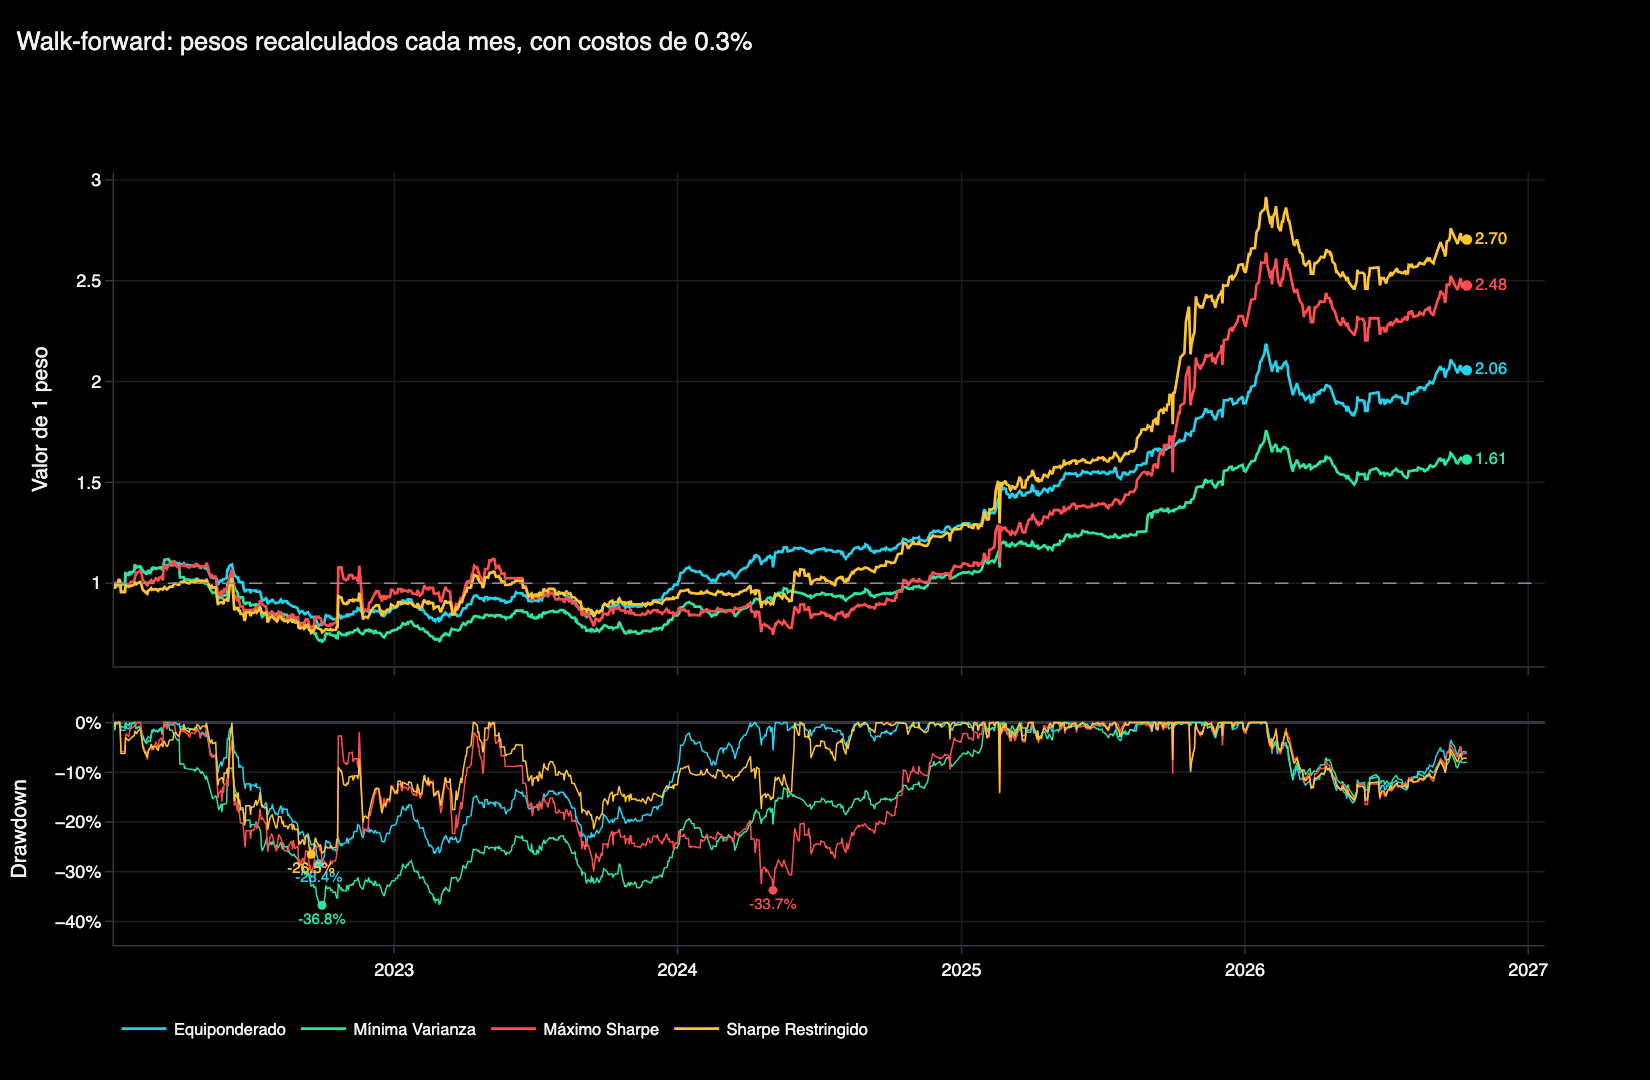

In [30]:
# Gráfica: valor de 1 peso (arriba) y drawdown (abajo)
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.68, 0.32], vertical_spacing=0.06)

for i in range(4):
    nombre = nombres[i]
    color = colores_port[i]
    valor = valor_wf[nombre]
    drawdown = (valor / valor.cummax() - 1) * 100

    # Línea del valor de 1 peso
    fig.add_trace(go.Scatter(x=valor.index, y=valor, mode='lines', name=nombre, legendgroup=nombre,
                             line=dict(color=color, width=1.8),
                             hovertemplate=nombre + ': %{y:.2f}'), row=1, col=1)

    # Punto final con su valor escrito al lado
    fig.add_trace(go.Scatter(x=[valor.index[-1]], y=[valor.iloc[-1]], mode='markers+text',
                             text=[f'{valor.iloc[-1]:.2f}'], textposition='middle right',
                             textfont=dict(size=11, color=color), marker=dict(size=7, color=color),
                             legendgroup=nombre, showlegend=False, hoverinfo='skip'), row=1, col=1)

    # Drawdown
    fig.add_trace(go.Scatter(x=drawdown.index, y=drawdown, mode='lines', name=nombre, legendgroup=nombre,
                             showlegend=False, line=dict(color=color, width=1),
                             hovertemplate=nombre + ': %{y:.1f}%'), row=2, col=1)

    # Peor caída con su valor escrito
    fig.add_trace(go.Scatter(x=[drawdown.idxmin()], y=[drawdown.min()], mode='markers+text',
                             text=[f'{drawdown.min():.1f}%'], textposition='bottom center',
                             textfont=dict(size=10, color=color), marker=dict(size=6, color=color),
                             legendgroup=nombre, showlegend=False, hoverinfo='skip'), row=2, col=1)

# Línea de referencia: 1 peso (ni ganó ni perdió)
fig.add_hline(y=1, line_color=gris, line_dash='dash', line_width=1, row=1, col=1)

fig.update_yaxes(title_text='Valor de 1 peso', row=1, col=1)
fig.update_yaxes(title_text='Drawdown', ticksuffix='%', row=2, col=1,
                 range=[(valor_wf / valor_wf.cummax() - 1).min().min() * 100 - 8, 2])
fig.update_layout(title=f'Walk-forward: pesos recalculados cada mes, con costos de {costo_transaccion:.1%}',
                  height=720, hovermode='x unified',
                  legend=dict(orientation='h', yanchor='top', y=-0.08, x=0),
                  margin=dict(r=70, b=90))
fig.write_image(carpeta + '/walk_forward.png', scale=2, width=ancho_imagen, height=720)   # imagen para el README
fig.show()

## 12. Contribución al riesgo y escenarios de estrés



Contribución al riesgo del Máximo Sharpe:
           Peso (%)  Contribución (%)  Contribución / Peso
NUTRESA       32.03             60.46                 1.89
TERPEL        28.92             15.21                 0.53
CIBEST        17.94             12.70                 0.71
MINEROS       10.47              8.16                 0.78
BVC            7.29              2.19                 0.30
GRUPOSURA      1.69              0.81                 0.48
CEMARGOS       1.66              0.47                 0.28
Suma de contribuciones: 100.0 %

NUTRESA , TERPEL y CIBEST explican el 88.4 % del riesgo.


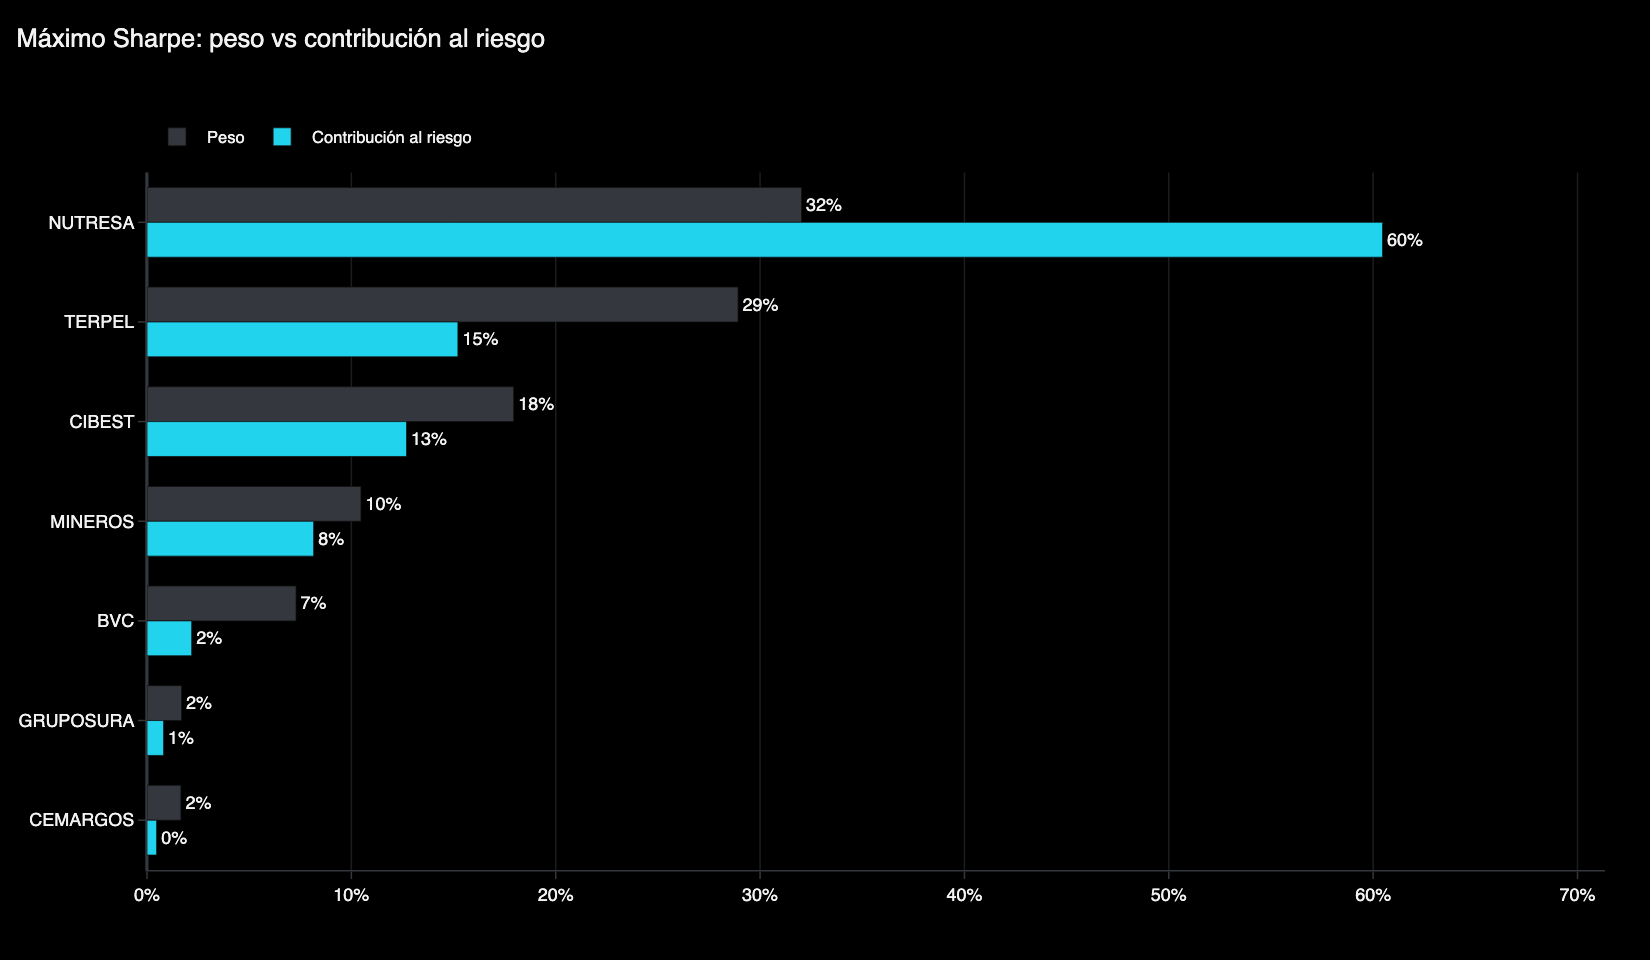

In [31]:
# Contribución al riesgo del Máximo Sharpe (pesos de la sección 6)
w = w_sharpe
r_p = retornos_diarios['Máximo Sharpe']     # serie de retornos simples del portafolio

# Covarianza de cada acción con el portafolio
cov_con_portafolio = []
for accion in activos:
    cov_con_portafolio.append(np.cov(retornos_portafolio[accion], r_p)[0, 1])
cov_con_portafolio = np.array(cov_con_portafolio)

# Aporte de cada acción = peso x covarianza con el portafolio, y lo paso a % del total
aporte = w * cov_con_portafolio
contribucion = aporte / aporte.sum()

tabla_contrib = pd.DataFrame({
    'Peso (%)': w * 100,
    'Contribución (%)': contribucion * 100,
}, index=activos)

# Divido solo donde la acción tiene peso de verdad (más de 0.01%).
# El optimizador no deja los pesos en 0 exacto sino en 0.0000000001, y dividir por eso da números sin sentido
tabla_contrib['Contribución / Peso'] = tabla_contrib['Contribución (%)'] / tabla_contrib['Peso (%)'].where(tabla_contrib['Peso (%)'] > 0.01)
tabla_contrib = tabla_contrib.sort_values('Contribución (%)', ascending=False)

print("Contribución al riesgo del Máximo Sharpe:")
print(tabla_contrib.round(2).dropna())
print("Suma de contribuciones:", round(tabla_contrib['Contribución (%)'].sum(), 1), "%")

primera = tabla_contrib.index[0]
segunda = tabla_contrib.index[1]
tercera = tabla_contrib.index[2]
tres_primeras = tabla_contrib['Contribución (%)'].iloc[0] + tabla_contrib['Contribución (%)'].iloc[1] + tabla_contrib['Contribución (%)'].iloc[2]
print()
print(primera, ",", segunda, "y", tercera, "explican el",
    round(tres_primeras, 1), "% del riesgo.")

# Gráfica: peso vs contribución al riesgo
# Solo dibujo las acciones que tienen peso (más de 0.01%); las que quedaron en 0 no aparecen
tabla_grafica = tabla_contrib[tabla_contrib['Peso (%)'] > 0.01]

textos_peso = []
textos_contrib = []
for k in range(len(tabla_grafica)):
    textos_peso.append(f"{tabla_grafica['Peso (%)'].iloc[k]:.0f}%")
    textos_contrib.append(f"{tabla_grafica['Contribución (%)'].iloc[k]:.0f}%")

fig = go.Figure()
fig.add_trace(go.Bar(y=tabla_grafica.index, x=tabla_grafica['Peso (%)'], orientation='h', name='Peso',
                     marker_color=gris_oscuro, text=textos_peso, textposition='outside', cliponaxis=False,
                     hovertemplate='%{y}: %{x:.1f}% del capital'))
fig.add_trace(go.Bar(y=tabla_grafica.index, x=tabla_grafica['Contribución (%)'], orientation='h',
                     name='Contribución al riesgo', marker_color=cyan, text=textos_contrib,
                     textposition='outside', cliponaxis=False,
                     hovertemplate='%{y}: %{x:.1f}% del riesgo'))

maximo = max(tabla_grafica['Peso (%)'].max(), tabla_grafica['Contribución (%)'].max())
minimo = min(tabla_grafica['Contribución (%)'].min(), 0)
fig.update_xaxes(range=[minimo * 1.2, maximo * 1.18], ticksuffix='%')
fig.update_yaxes(autorange='reversed', showgrid=False)
fig.update_layout(title='Máximo Sharpe: peso vs contribución al riesgo',
                  barmode='group', height=60 * len(tabla_grafica) + 220, bargap=0.3)
fig.write_image(carpeta + '/contribucion_riesgo.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()


Retorno (%) de cada portafolio en cada escenario:
                                Equiponderado  Mínima Varianza  Máximo Sharpe  Sharpe Restringido
Peores 3 meses 06/2022-09/2022          -21.9            -20.2          -13.9               -15.2
Elecciones jun-jul 2022                 -14.4            -13.9           -9.1                -8.8
Elecciones jun-jul 2026                   1.9              1.2            2.0                 1.7
Último año                               20.7             16.5           42.8                34.7
NUTRESA cae 30% (resto quieto)           -1.5             -1.6           -9.6                -9.7
TERPEL cae 30% (resto quieto)            -1.5             -3.8           -8.7                -5.2


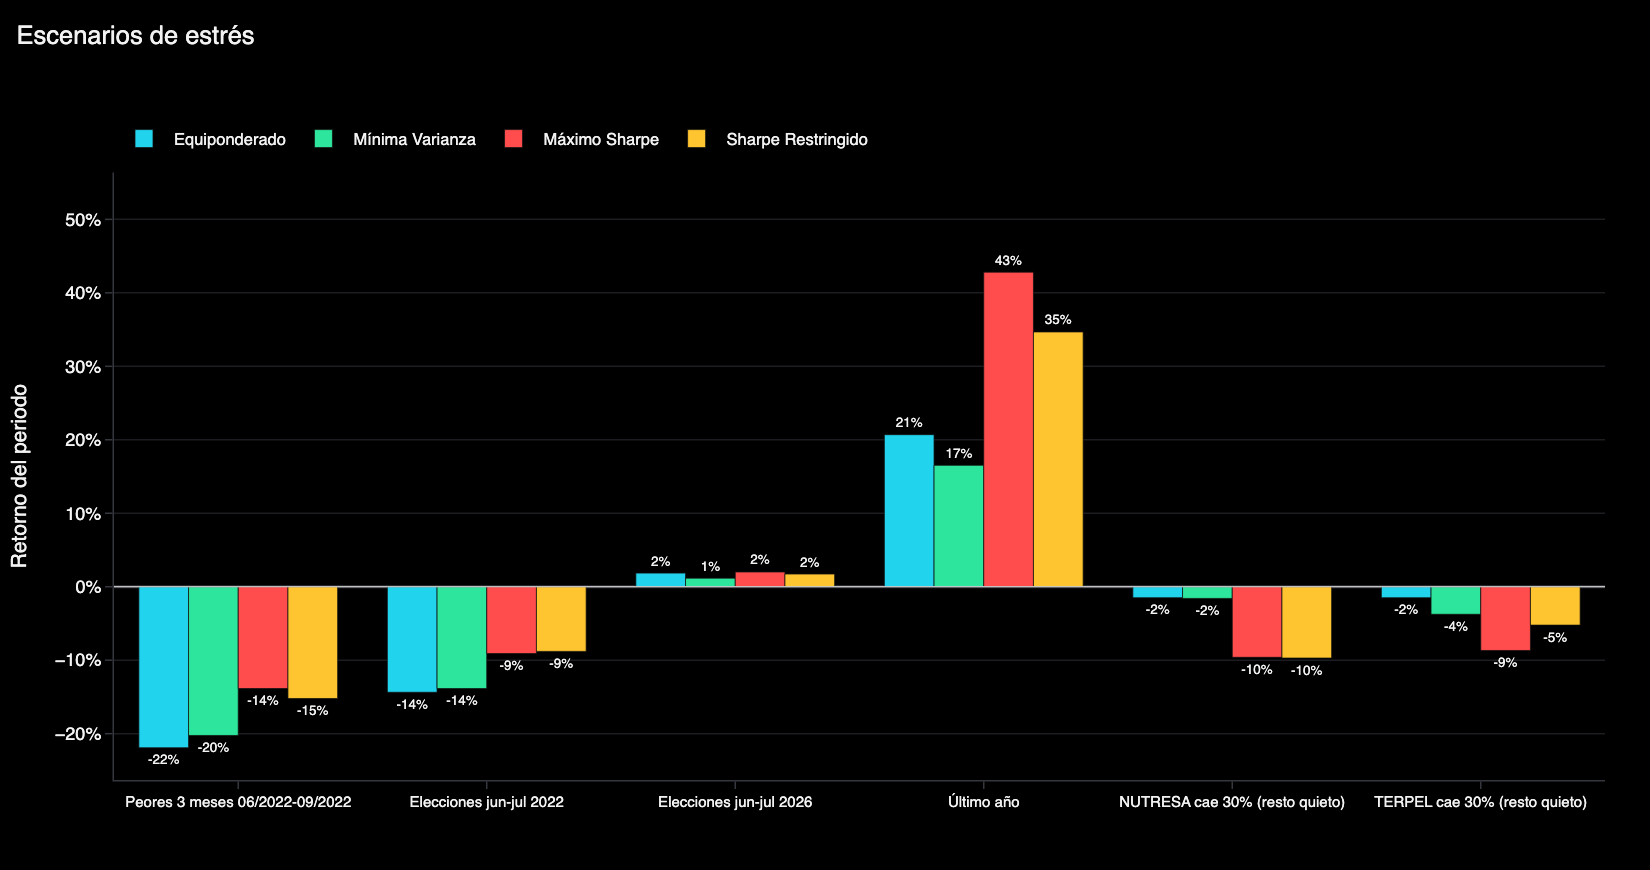

In [32]:
# Escenarios de estrés

# Los peores 3 meses (63 días de bolsa) del equiponderado
valor_equi = (1 + retornos_diarios['Equiponderado']).cumprod()
cambio_3_meses = valor_equi / valor_equi.shift(63) - 1
fin_peor = cambio_3_meses.idxmin()
posicion_fin = list(valor_equi.index).index(fin_peor)
inicio_peor = valor_equi.index[posicion_fin - 62]

primer_dia = retornos_diarios.index[0]
ultimo_dia = retornos_diarios.index[-1]

# Cada escenario: [nombre, fecha de inicio, fecha de fin]
escenarios_posibles = [
    ['Peores 3 meses ' + inicio_peor.strftime('%m/%Y') + '-' + fin_peor.strftime('%m/%Y'), inicio_peor, fin_peor],
    ['Elecciones jun-jul 2022', '2022-06-01', '2022-07-31'],
    ['Elecciones jun-jul 2026', '2026-06-01', '2026-07-31'],
    ['Último año', ultimo_dia - pd.Timedelta(days=365), ultimo_dia],
]

# Solo uso los escenarios que caen completos dentro de las fechas de los datos
escenarios = []
for escenario in escenarios_posibles:
    if pd.Timestamp(escenario[1]) >= primer_dia and pd.Timestamp(escenario[2]) <= ultimo_dia:
        escenarios.append(escenario)

tabla_estres = pd.DataFrame(columns=nombres, dtype=float)

for escenario in escenarios:
    nombre_escenario = escenario[0]
    tramo = retornos_diarios.loc[escenario[1]:escenario[2]]

    for nombre in nombres:
        # Retorno del periodo = producto de (1 + retorno diario) - 1
        tabla_estres.loc[nombre_escenario, nombre] = ((1 + tramo[nombre]).prod() - 1) * 100

# Hipotético: cae 30% cada una de las dos acciones con más peso en el Máximo Sharpe
pesos_sharpe = pd.Series(w_sharpe, index=activos).sort_values(ascending=False)

for accion in pesos_sharpe.index[:2]:
    j = activos.index(accion)
    nombre_escenario = accion + ' cae 30% (resto quieto)'
    for i in range(4):
        tabla_estres.loc[nombre_escenario, nombres[i]] = -30 * lista_pesos[i][j]

print()
print("Retorno (%) de cada portafolio en cada escenario:")
print(tabla_estres.round(1))

# Gráfica
fig = go.Figure()

for i in range(4):
    valores = tabla_estres[nombres[i]].values
    textos = []
    for v in valores:
        textos.append(f'{v:.0f}%')

    fig.add_trace(go.Bar(x=tabla_estres.index, y=valores, name=nombres[i], marker_color=colores_port[i],
                         text=textos, textposition='outside', textfont=dict(size=9), cliponaxis=False,
                         hovertemplate=nombres[i] + ': %{y:.1f}%'))

fig.add_hline(y=0, line_color=blanco, line_width=0.8)
fig.update_xaxes(tickfont=dict(size=10), showgrid=False)
fig.update_yaxes(title_text='Retorno del periodo', ticksuffix='%',
                 range=[min(tabla_estres.min().min(), 0) * 1.2, max(tabla_estres.max().max(), 0) * 1.2 + 5])
fig.update_layout(title='Escenarios de estrés',
                  barmode='group', height=580, bargap=0.2)
fig.write_image(carpeta + '/escenarios_estres.png', scale=2, width=ancho_imagen)   # imagen para el README
fig.show()

In [33]:
# Sensibilidad: ¿cambia el mejor portafolio si cambia la tasa libre de riesgo?
tasas_prueba = sorted(set([0.06, 0.09, rf, 0.15]))   # ordenadas y sin repetir
tabla_rf = pd.DataFrame(columns=nombres, dtype=float)

for tasa in tasas_prueba:
    for nombre in nombres:
        ret = tabla_comparacion.loc[nombre, 'Retorno']
        vol = tabla_comparacion.loc[nombre, 'Volatilidad']
        tabla_rf.loc['rf ' + str(round(tasa * 100, 2)) + '%', nombre] = (ret - tasa) / vol

print("Sharpe con distintas tasas libres de riesgo:")
print(tabla_rf.round(2))
print()
print("Mejor portafolio con cada tasa:")
for fila in tabla_rf.index:
    print(" ", fila, "->", tabla_rf.loc[fila].idxmax())

Sharpe con distintas tasas libres de riesgo:
           Equiponderado  Mínima Varianza  Máximo Sharpe  Sharpe Restringido
rf 6.0%             0.56             0.36           1.36                1.21
rf 9.0%             0.36             0.13           1.23                1.07
rf 12.25%           0.14            -0.11           1.10                0.93
rf 15.0%           -0.05            -0.32           0.98                0.81

Mejor portafolio con cada tasa:
  rf 6.0% -> Máximo Sharpe
  rf 9.0% -> Máximo Sharpe
  rf 12.25% -> Máximo Sharpe
  rf 15.0% -> Máximo Sharpe


## 13. Resumen y conclusiones



In [34]:
# ============================================================
# RESUMEN Y CONCLUSIÓN DEL PORTAFOLIO
# Todo el texto sale de los datos: si cambian, las frases cambian.
# ============================================================

# ---------- Parámetros del resumen ----------
umbral_concentracion = 55     # % del riesgo en 3 acciones para decir que está concentrado
umbral_caida_sharpe = 0.3     # si pierde más del 30% del Sharpe fuera de muestra, se explica por qué

# ---------- Variables que se usan varias veces ----------
ms = tabla_ratios.loc['Máximo Sharpe']        # con los datos conocidos
ms_wf = tabla_wf.loc['Máximo Sharpe']         # sin conocer el futuro (walk-forward)
eq_wf = tabla_wf.loc['Equiponderado']
mejor_papel = tabla_ratios['Sharpe'].idxmax() # el mejor con los datos conocidos
mejor_wf = tabla_wf['Sharpe'].idxmax()        # el mejor sin conocer el futuro

pesos_ms = pd.Series(w_sharpe, index=activos).sort_values(ascending=False)
con_peso = pesos_ms[pesos_ms > 0.0001]        # acciones que sí tienen peso
accion_mayor = pesos_ms.index[0]              # la de más peso
concentrado = tres_primeras > umbral_concentracion
r_ms = retornos_diarios['Máximo Sharpe']

# VaR y CVaR Monte Carlo t-Student (en valor positivo = pérdida)
var95 = abs(tabla_var.loc['Máximo Sharpe', 'MC t 95%'])
var99 = abs(tabla_var.loc['Máximo Sharpe', 'MC t 99%'])
cvar95 = abs(tabla_cvar.loc['Máximo Sharpe', 'MC t 95%'])
cvar99 = abs(tabla_cvar.loc['Máximo Sharpe', 'MC t 99%'])


# ============================================================
# 1. DATOS
# ============================================================
print("=" * 60)
print("1. DATOS")
print("=" * 60)
print(f"{len(precios.columns)} acciones descargadas, {len(pasan)} pasan el filtro de liquidez")
print(f"Días usados: {len(retornos_portafolio)} "
      f"({retornos_portafolio.index[0].date()} a {retornos_portafolio.index[-1].date()})")

print("\nCon los datos conocidos:")
print(tabla_ratios[['Retorno (%)', 'Volatilidad (%)', 'Sharpe', 'Máx DD (%)']].round(2))

print("\nSin conocer el futuro (walk-forward, con costos):")
print(tabla_wf[['1 peso termina en', 'Retorno (%)', 'Sharpe', 'Máx DD (%)', 'Rotación mensual (%)']].round(2))


# ============================================================
# 2. QUÉ ESCOGIÓ EL OPTIMIZADOR
# ============================================================
# Las 5 acciones con más peso, en texto
principales = []
for accion in con_peso.index[:5]:
    principales.append(f"{accion} {con_peso[accion]:.0%}")

# Cuántas acciones le ganaron a la tasa libre de riesgo
le_ganan_rf = retorno_anual[retorno_anual > rf]

print("\n2. QUÉ ESCOGIÓ EL OPTIMIZADOR")
print(f"   Usa {len(con_peso)} de {n} acciones. Las principales: {', '.join(principales)}.")
print(f"   {len(le_ganan_rf)} de {n} acciones le ganaron a la tasa libre de riesgo ({rf:.2%}).")
if prom_corr < 0.3:
    print(f"   Correlación promedio baja ({prom_corr:.2f}): puede juntar ganadoras sin sumar mucho riesgo.")
else:
    print(f"   Correlación promedio alta ({prom_corr:.2f}): diversificar ayuda poco.")


# ============================================================
# 3. DESEMPEÑO CON LOS DATOS CONOCIDOS
# ============================================================
tasas_que_gana = (tabla_rf.idxmax(axis=1) == 'Máximo Sharpe').sum()
azar_le_ganan = (sharpe_azar > ms['Sharpe']).sum()

print("\n3. CON LOS DATOS CONOCIDOS")
print(f"   Retorno {ms['Retorno (%)']:.1f}% anual | Volatilidad {ms['Volatilidad (%)']:.1f}% | "
      f"Sharpe {ms['Sharpe']:.2f} | Máx. DD {ms['Máx DD (%)']:.1f}%")
if mejor_papel == 'Máximo Sharpe':
    print("   Es el de mayor Sharpe de los cuatro.")
else:
    print(f"   El de mayor Sharpe fue el {mejor_papel} ({tabla_ratios.loc[mejor_papel, 'Sharpe']:.2f}).")
print(f"   {azar_le_ganan} de {len(sharpe_azar)} portafolios al azar le ganaron "
      f"(el mejor llegó a {sharpe_azar.max():.2f}).")
print(f"   Gana en {tasas_que_gana} de {len(tabla_rf)} tasas libres de riesgo probadas "
      f"({tasas_prueba[0]:.0%} a {tasas_prueba[-1]:.0%}).")


# ============================================================
# 4. RIESGO
# ============================================================
escenario_mayor = accion_mayor + ' cae 30% (resto quieto)'

# Caídas históricas: escenarios donde el equiponderado perdió
caidas = []
aguanta = 0
for escenario in escenarios:
    nombre = escenario[0]
    if tabla_estres.loc[nombre, 'Equiponderado'] < 0:
        caidas.append(nombre)
        if tabla_estres.loc[nombre, 'Máximo Sharpe'] > tabla_estres.loc[nombre, 'Equiponderado']:
            aguanta = aguanta + 1

# Pruebas del VaR (Kupiec = cantidad de violaciones, Christoffersen = rachas)
# Solo el Monte Carlo t, que es el método de las conclusiones
backtest_ms = backtest_mct[backtest_mct['Portafolio'] == 'Máximo Sharpe']
falla_cantidad = list(backtest_ms[backtest_ms['Cantidad OK'] == 'NO']['Nivel'])
falla_rachas = list(backtest_ms[backtest_ms['Sin rachas'] == 'NO']['Nivel'])

print("\n4. RIESGO DEL MÁXIMO SHARPE")
print(f"   {primera}, {segunda} y {tercera} explican el {tres_primeras:.0f}% del riesgo.")
if concentrado:
    print("   En la práctica es una apuesta a 3 acciones.")
print(f"   Si {accion_mayor} cae 30%, el portafolio pierde {-tabla_estres.loc[escenario_mayor, 'Máximo Sharpe']:.1f}% "
      f"(equiponderado: {-tabla_estres.loc[escenario_mayor, 'Equiponderado']:.1f}%).")
if len(caidas) > 0:
    print(f"   Perdió menos que el equiponderado en {aguanta} de {len(caidas)} caídas históricas.")

print(f"   Con un capital de ${capital:,.0f} COP (Monte Carlo t-Student con {grados_libertad} g.l. escogidos por máxima verosimilitud, 1 día):")
print(f"     VaR 95%:  {var95:.2%} = ${var95 * capital:,.0f}  | CVaR 95%: {cvar95:.2%} = ${cvar95 * capital:,.0f}")
print(f"     VaR 99%:  {var99:.2%} = ${var99 * capital:,.0f}  | CVaR 99%: {cvar99:.2%} = ${cvar99 * capital:,.0f}")
print(f"   O sea: 1 de cada 100 días se puede perder más de {var99:.2%}, y ese día "
      f"la pérdida promedio es {cvar99:.2%}.")
print(f"   Peor día real: {r_ms.min():.2%} el {r_ms.idxmin().date()}.")

if len(falla_cantidad) == 0 and len(falla_rachas) == 0:
    print("   El VaR Monte Carlo t pasa Kupiec y Christoffersen.")
if len(falla_cantidad) > 0:
    print(f"   El VaR Monte Carlo t falla Kupiec al {', '.join(falla_cantidad)}: no acierta la cantidad de violaciones.")
if len(falla_rachas) > 0:
    print(f"   El VaR Monte Carlo t falla Christoffersen al {', '.join(falla_rachas)}: las pérdidas grandes llegan juntas.")


# ============================================================
# 5. SIN MIRAR EL FUTURO
# ============================================================
cambio_sharpe = ms_wf['Sharpe'] / ms['Sharpe'] - 1   # negativo = pierde Sharpe

print("\n5. SIN MIRAR EL FUTURO (WALK-FORWARD, CON COSTOS)")
print(f"   Sharpe: {ms['Sharpe']:.2f} -> {ms_wf['Sharpe']:.2f} ({cambio_sharpe:+.0%}).")
print(f"   1 peso terminó en {ms_wf['1 peso termina en']:.2f} "
      f"(equiponderado: {eq_wf['1 peso termina en']:.2f}), con costo de {costo_transaccion:.1%} por peso negociado.")
print(f"   Rota el {ms_wf['Rotación mensual (%)']:.0f}% del portafolio cada mes "
      f"(el que menos rota: {tabla_wf['Rotación mensual (%)'].idxmin()}, "
      f"{tabla_wf['Rotación mensual (%)'].min():.0f}%).")

# Si pierde mucho Sharpe, explicarlo con los datos
if cambio_sharpe < -umbral_caida_sharpe:
    otras = retorno_anual.drop(accion_mayor)
    print("   ¿Por qué? El optimizador trata el retorno pasado como seguro.")
    print(f"   Ej: {accion_mayor} tiene el {pesos_ms[accion_mayor]:.0%} del peso porque rindió "
          f"{retorno_anual[accion_mayor]:.1%} al año (la mediana de las demás: {otras.median():.1%}).")
    if ms_wf['Rotación mensual (%)'] > tabla_wf['Rotación mensual (%)'].median():
        print("   Además rota más que la mayoría, así que paga más costos.")


# ============================================================
# CONCLUSIÓN
# ============================================================
print("\n" + "=" * 60)
print("CONCLUSIÓN.. ELECCION MAXIMO SHARPE PERO CONSIDERAR LA RESTRICCION DE SHARPE CON LOS PESOS TAMBIEN")
print("=" * 60)
print(f"Con los datos conocidos, el mejor es el {mejor_papel} "
      f"(Sharpe {tabla_ratios.loc[mejor_papel, 'Sharpe']:.2f}).")
print(f"Sin conocer el futuro, el mejor es el {mejor_wf} "
      f"(Sharpe {tabla_wf.loc[mejor_wf, 'Sharpe']:.2f}, 1 peso -> {tabla_wf.loc[mejor_wf, '1 peso termina en']:.2f}).")
print(f"Se puede considerar tambien elegir  {mejor_wf}, porque la prueba sin conocer el futuro es la más realista y la restriccion de pesos obliga a considerar mayor diviersificacion ")

# Por qué ese portafolio aguanta mejor (según cuál sea)
if mejor_wf == 'Sharpe Restringido':
    print(f"Obliga a tener entre {peso_min:.0%} y {peso_max:.0%} por acción, así que un error al estimar")
    print("el retorno de una acción pesa menos.")
elif mejor_wf == 'Mínima Varianza':
    print("No usa el retorno esperado (lo más difícil de estimar), solo la covarianza.")
elif mejor_wf == 'Equiponderado':
    print("No estima nada: reparte igual entre todas las acciones.")

if concentrado and mejor_wf == 'Máximo Sharpe':
    print(f"Ojo: su riesgo depende sobre todo de {primera} y {segunda}.")

# Riesgo del portafolio escogido
print(f"Riesgo diario del {mejor_wf} (MC t 99%): VaR {abs(tabla_var.loc[mejor_wf, 'MC t 99%']):.2%}, "
      f"CVaR {abs(tabla_cvar.loc[mejor_wf, 'MC t 99%']):.2%} "
      f"(${abs(tabla_cvar.loc[mejor_wf, 'MC t 99%']) * capital:,.0f} COP).")




# ============================================================

1. DATOS
30 acciones descargadas, 20 pasan el filtro de liquidez
Días usados: 1425 (2021-01-18 a 2026-10-14)

Con los datos conocidos:
                    Retorno (%)  Volatilidad (%)  Sharpe  Máx DD (%)
Equiponderado             14.33            14.94    0.14      -28.38
Mínima Varianza           10.78            13.36   -0.11      -30.80
Máximo Sharpe             38.69            24.12    1.10      -23.16
Sharpe Restringido        33.17            22.50    0.93      -25.14

Sin conocer el futuro (walk-forward, con costos):
                    1 peso termina en  Retorno (%)  Sharpe  Máx DD (%)  Rotación mensual (%)
Equiponderado                    2.06        16.69    0.28      -28.38                  0.00
Mínima Varianza                  1.61        11.51   -0.05      -36.75                  7.74
Máximo Sharpe                    2.48        24.14    0.38      -33.72                 26.50
Sharpe Restringido               2.70        24.35    0.49      -26.51                 14.62

2. 